# Reto F1: predicción del resultado de un Gran Premio

## El problema en pocas palabras

Somos el equipo de datos de una escudería. Es sábado por la noche: la clasificación ya se ha disputado y sabemos en qué posición sale cada piloto el domingo. El jefe de estrategia quiere dos cosas para la carrera:

1. **Probabilidades.** Para cada piloto, la probabilidad de terminar en el podio (posiciones 1 a 3) y en los puntos (posiciones 1 a 10).
2. **Posición.** Un número por piloto que indique en qué orden creemos que van a terminar.

Es un problema de *machine learning* supervisado: aprendemos de carreras pasadas, donde conocemos el resultado, para predecir carreras en las que fingimos no conocerlo. El reto evalúa con la temporada 2024 (test) y nos deja aprender con todo lo anterior (train).

## Un poco de F1 para entender los datos

- **Fin de semana.** Entrenamientos libres el viernes, clasificación el sábado y carrera el domingo. Algunos fines de semana añaden una **sprint**, una carrera corta que se corre antes del Gran Premio.
- **Clasificación.** Tiene tres rondas eliminatorias: Q1 (todos), Q2 (los 15 mejores) y Q3 (los 10 mejores). El orden de la clasificación decide la **parrilla** (`grid`), la posición de salida del domingo.
- **Penalizaciones.** Si un piloto cambia piezas del motor por encima del límite, o comete una infracción, pierde puestos en la parrilla. Por eso la parrilla no siempre coincide con el orden de la clasificación.
- **Puntos.** Desde 2010 puntúan los 10 primeros (25, 18, 15, 12, 10, 8, 6, 4, 2, 1). La suma a lo largo del año es el **mundial** de pilotos y el de constructores (equipos).
- **Abandonos.** Un coche puede no terminar por avería o accidente. En los datos esos pilotos aparecen al final del orden.

## La regla más importante: no mirar el futuro

Predecimos el sábado por la noche, así que solo podemos usar lo que se sabe en ese momento: la parrilla, la clasificación, la sprint de ese fin de semana y todo lo que pasó en carreras **anteriores**. Si un modelo usa, aunque sea sin querer, algo que solo se conoce después de la carrera (por ejemplo, los puntos que ganó ese día), sus resultados parecerán buenísimos y serán falsos. A este error se le llama **fuga de información** (*data leakage*) y en el reto descalifica.

## Plan del notebook

1. Configuración y carga de datos
2. Entender las tablas y unirlas en una tabla piloto-carrera
3. Lista de variables prohibidas
4. EDA (análisis exploratorio)
5. Ingeniería de variables
6. Validación temporal, métricas y referencia de parrilla
7. Parte 1: probabilidades
8. Parte 2: posición
9. Análisis de errores
10. Entrega: entrenar con 2014-2023, predecir 2024 y exportar

Las secciones 1 a 3 no entrenan ningún modelo. Sirven para entender los datos y dejar preparada una tabla limpia sobre la que construir todo lo demás.

## 1. Configuración y carga de datos

**Qué hace esta celda.** Importa las librerías, fija la semilla aleatoria y lee los 13 CSV del dataset en un diccionario llamado `tablas`, donde cada clave es el nombre del fichero.

**Por qué.**

- `SEED = 2502` lo exige el reto. Los modelos que usaremos tienen partes aleatorias; fijando la semilla, quien vuelva a ejecutar el notebook obtiene exactamente los mismos números.
- `DATA_DIR = Path(".")` indica que los CSV están en la misma carpeta que el notebook, que es como lo ejecutará el organizador.
- Los CSV de este dataset escriben `\N` cuando falta un dato. Con `na_values="\\N"` pandas lo convierte en un valor vacío (`NaN`) en lugar de tratarlo como texto.

**Qué mirar en la salida.** El número de filas de cada tabla. `results` tiene unas 26.700 filas: una por cada piloto en cada Gran Premio desde 1950. Es la tabla central del proyecto.

In [1]:
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100

# Semilla fija para que todo sea reproducible
SEED = 2502
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = Path(".")   # los CSV están junto al notebook
TEST_YEAR = 2024       # temporada que se evalúa


def leer(nombre):
    """Lee un CSV del dataset tratando '\\N' como valor ausente."""
    return pd.read_csv(DATA_DIR / f"{nombre}.csv", na_values="\\N")


tablas = {n: leer(n) for n in [
    "results", "races", "drivers", "constructors", "qualifying", "sprint_results",
    "driver_standings", "constructor_standings", "constructor_results",
    "lap_times", "pit_stops", "status", "circuits",
]}
for n, t in tablas.items():
    print(f"{n:24s} {t.shape[0]:>8,} filas  {t.shape[1]:>3} columnas")

results                    26,759 filas   18 columnas
races                       1,125 filas   18 columnas
drivers                       861 filas    9 columnas
constructors                  212 filas    5 columnas
qualifying                 10,494 filas    9 columnas
sprint_results                360 filas   16 columnas
driver_standings           34,863 filas    7 columnas
constructor_standings      13,391 filas    7 columnas
constructor_results        12,625 filas    5 columnas
lap_times                 589,081 filas    6 columnas
pit_stops                  11,371 filas    7 columnas
status                        139 filas    2 columnas
circuits                       77 filas    9 columnas


**Qué contiene cada tabla** (las que más usaremos, en negrita):

| Tabla | Una fila es… | Para qué nos sirve |
|---|---|---|
| **`results`** | un piloto en un Gran Premio | la unidad de predicción y el objetivo (`positionOrder`) |
| **`races`** | un Gran Premio | año, ronda, fecha y circuito |
| **`qualifying`** | un piloto en una clasificación | tiempos de Q1, Q2 y Q3 del sábado |
| `sprint_results` | un piloto en una sprint | resultado de la sprint del fin de semana |
| `driver_standings` | un piloto tras una carrera | el mundial de pilotos acumulado |
| `constructor_standings` | un equipo tras una carrera | el mundial de constructores acumulado |
| `constructor_results` | un equipo en una carrera | puntos del equipo en esa carrera |
| `lap_times` | una vuelta de un piloto | ritmo en carrera (solo de carreras pasadas) |
| `pit_stops` | una parada en boxes | paradas (solo de carreras pasadas) |
| `status` | un código de estado final | traduce `statusId` a texto: "Finished", "Engine", "Accident"… |
| `drivers`, `constructors`, `circuits` | un piloto, equipo o circuito | nombres y datos descriptivos |

**Qué hace esta celda.** Comprueba qué años trae el dataset y elimina cualquier temporada posterior a 2024, tanto en `races` como en las tablas que dependen de una carrera.

**Por qué.** El reto dice que, si el dataset trae 2025, hay que quitarlo. Nuestra versión acaba en 2024, pero dejamos el filtro para que el notebook funcione igual con una versión más nueva.

In [2]:
races = tablas["races"]
print("Años disponibles:", races.year.min(), "-", races.year.max())
print("Carreras por año (últimos):", races.groupby("year").size().tail(4).to_dict())

races = races[races.year <= TEST_YEAR].copy()
ids_validos = set(races.raceId)
for n in ["results", "qualifying", "sprint_results", "driver_standings",
          "constructor_standings", "constructor_results", "lap_times", "pit_stops"]:
    tablas[n] = tablas[n][tablas[n].raceId.isin(ids_validos)].copy()
tablas["races"] = races

Años disponibles: 1950 - 2024
Carreras por año (últimos): {2021: 22, 2022: 22, 2023: 22, 2024: 24}


## 2. Entender las tablas y unirlas a nivel piloto-carrera

### 2.1 El orden de las carreras

Muchas de las variables que crearemos dependen de "lo que pasó antes": la media de las últimas cinco carreras, el mundial antes de esta carrera, etc. Para eso necesitamos ordenar las carreras en el tiempo sin errores.

**Qué hace esta celda.** Comprueba si el identificador de carrera (`raceId`) sigue el orden cronológico. Después ordena las carreras por fecha y crea `race_idx`, un número que vale 0 para la primera carrera de la historia, 1 para la segunda, y así sucesivamente. También marca qué fines de semana tuvieron sprint (`has_sprint`).

**Qué mirar en la salida.** La comprobación da `False`: 2009 tiene los `raceId` 1 a 17 y 2008 los 18 a 35. El dataset se creó empezando por 2009 y las temporadas antiguas se añadieron después. Si usáramos `raceId` para decidir qué carrera va antes, mezclaríamos el pasado con el futuro. Por eso a partir de aquí todo se ordena con `race_idx`.

In [3]:
orden = races.sort_values(["year", "round"])
print("¿raceId crece con (year, round)?", orden.raceId.is_monotonic_increasing)
print(orden[orden.year.isin([1950, 2008, 2009])].groupby("year").raceId.agg(["min", "max"]))

races["date"] = pd.to_datetime(races["date"])
races = races.sort_values(["date", "raceId"]).reset_index(drop=True)
races["race_idx"] = np.arange(len(races))  # 0, 1, 2… en orden cronológico
races["has_sprint"] = races.raceId.isin(tablas["sprint_results"].raceId)

¿raceId crece con (year, round)? False
      min  max
year          
1950  833  839
2008   18   35
2009    1   17


### 2.2 Tabla base: una fila por piloto y carrera

Los datos están repartidos en varias tablas relacionadas por identificadores (`raceId`, `driverId`, `constructorId`, `statusId`). Para trabajar cómodamente las juntamos en una sola tabla, `base`, con una fila por piloto y carrera.

**Qué hace esta celda.** Parte de `results` y, con `merge` (el equivalente a un JOIN de SQL), le añade:

- de `races`: año, ronda, fecha, `race_idx`, circuito, nombre del GP y si hubo sprint;
- de `status`: el texto del estado final ("Finished", "Engine"…);
- de `drivers` y `constructors`: el nombre corto del piloto y del equipo.

Después comprueba dos cosas: que todas las filas han encontrado su carrera y si hay pilotos repetidos en una misma carrera.

**Una advertencia.** `base` contiene columnas que describen el resultado de la carrera (posición, puntos, estado final). Las necesitamos para entender los datos y, más adelante, para calcular estadísticas de carreras **pasadas**. Lo que nunca haremos es usarlas como entrada del modelo para la carrera que se predice. La sección 3 lo deja por escrito.

**Qué mirar en la salida.** Cero filas sin carrera, y 91 duplicados que son todos anteriores a 1979: en esa época dos pilotos podían compartir coche en una misma carrera. No afectan a los años que usaremos. La tabla final muestra las últimas filas: el GP de Abu Dabi 2024.

In [4]:
res = tablas["results"]
base = (
    res
    .merge(races[["raceId", "year", "round", "date", "race_idx", "circuitId", "name", "has_sprint"]],
           on="raceId", how="left")
    .merge(tablas["status"], on="statusId", how="left")
    .merge(tablas["drivers"][["driverId", "driverRef", "dob"]], on="driverId", how="left")
    .merge(tablas["constructors"][["constructorId", "constructorRef"]], on="constructorId", how="left")
    .sort_values(["race_idx", "positionOrder"])
    .reset_index(drop=True)
)
print(base.shape)
print("Filas sin carrera asociada:", base.year.isna().sum())
print("Duplicados piloto-carrera:", base.duplicated(["raceId", "driverId"]).sum(),
      "| último año con duplicados:", base[base.duplicated(["raceId", "driverId"], keep=False)].year.max())
base[["resultId", "year", "round", "name", "driverRef", "constructorRef", "grid",
      "positionText", "positionOrder", "status"]].tail(5)

(26759, 29)
Filas sin carrera asociada: 0
Duplicados piloto-carrera: 91 | último año con duplicados: 1978


,resultId,year,round,name,driverRef,constructorRef,grid,positionText,positionOrder,status
26754,26760,2024,24,Abu Dhabi Grand Prix,kevin_magnussen,haas,14,16,16,+1 Lap
26755,26761,2024,24,Abu Dhabi Grand Prix,lawson,rb,12,17,17,Engine
26756,26762,2024,24,Abu Dhabi Grand Prix,bottas,sauber,9,R,18,Collision damage
26757,26763,2024,24,Abu Dhabi Grand Prix,colapinto,williams,20,R,19,Engine
26758,26764,2024,24,Abu Dhabi Grand Prix,perez,red_bull,10,R,20,Collision


### 2.3 La variable objetivo y cómo se codifican los abandonos

**La variable objetivo** es lo que queremos predecir. El reto usa `positionOrder`, y conviene entender por qué no `position`:

- `position` es la posición oficial y queda vacía si el piloto no es clasificado (por ejemplo, si abandona).
- `positionOrder` siempre tiene valor: ordena primero a los clasificados y después, al final, a los que no terminaron.
- `positionText` dice por qué un piloto no tiene posición oficial:

| Código | Significado |
|---|---|
| número | clasificado en esa posición |
| R | retirado (abandono) |
| D | descalificado |
| E | excluido |
| W | retirado antes de la salida (*withdrawn*) |
| F | no se clasificó para la carrera |
| N | no clasificado (no completó el 90 % de la distancia) |

**Qué hace esta celda.**

1. Crea los dos objetivos de la Parte 1 como columnas de 0 y 1: `podio` (1 si `positionOrder ≤ 3`) y `top10` (1 si `positionOrder ≤ 10`).
2. Clasifica cada resultado en tres grupos a partir de `status`: **terminado** ("Finished" o "+1 Lap", "+2 Laps"…, que significa que acabó doblado), **abandono mecánico** (motor, caja de cambios, frenos…) y **abandono por accidente u otros** (choques, descalificaciones, lesiones…). Esto no es para predecir la carrera actual, sino para calcular más adelante la fiabilidad de cada coche con sus carreras anteriores.
3. Muestra cuántos resultados de cada tipo hay desde 2014 y los motivos de abandono más frecuentes.

**Qué mirar en la salida.** De unos 4.600 resultados desde 2014, unos 680 son abandonos (R): aproximadamente uno de cada siete. Es una fuente de error importante, porque un piloto puede salir primero y abandonar.

In [5]:
# Objetivos de la Parte 1 (solo se usan como respuesta, nunca como entrada)
base["podio"] = (base.positionOrder <= 3).astype(int)
base["top10"] = (base.positionOrder <= 10).astype(int)

# Terminó la carrera: "Finished" o doblado ("+1 Lap", "+2 Laps"...)
base["terminado"] = base.status.eq("Finished") | base.status.str.match(r"^\+\d+ Laps?$")

# Motivos que no son fallos del coche
ACCIDENTE = {"Accident", "Collision", "Spun off", "Collision damage", "Damage", "Debris",
             "Puncture", "Withdrew", "Disqualified", "Did not qualify", "Did not prequalify",
             "Excluded", "Not classified", "Driver Seat", "Injured", "Injury", "Illness",
             "Physical", "Fatal accident", "Eye injury", "Safety concerns", "107% Rule",
             "Underweight", "Launch control"}
base["abandono_mecanico"] = ~base.terminado & ~base.status.isin(ACCIDENTE)
base["abandono_accidente"] = ~base.terminado & base.status.isin(ACCIDENTE)

moderno = base[base.year >= 2014]
print("Desde 2014, positionText:")
print(moderno.positionText.where(~moderno.positionText.str.isnumeric(), "clasificado").value_counts())
print("\nStatus más frecuentes entre los que no terminan:")
print(moderno.loc[~moderno.terminado, "status"].value_counts().head(12))

Desde 2014, positionText:
positionText
clasificado    3905
R               680
W                28
D                11
N                 1
E                 1
Name: count, dtype: int64

Status más frecuentes entre los que no terminan:
status
Collision           150
Accident             85
Engine               81
Collision damage     59
Retired              50
Brakes               49
Gearbox              42
Power Unit           42
Suspension           25
Hydraulics           15
Electrical           14
Withdrew             14
Name: count, dtype: int64


**Qué hace esta celda.** Cuenta cuántos pilotos que no terminaron acabaron, aun así, con `positionOrder ≤ 10`.

**Por qué.** Como `positionOrder` ordena a los no clasificados por vueltas completadas, en teoría alguien que abandona en la última vuelta con muchos abandonos detrás podría quedar en el top 10. La salida muestra que desde 2014 ha pasado una sola vez. En la práctica, abandonar significa quedarse sin puntos, y eso hará que la probabilidad de abandono sea una variable útil.

In [6]:
print("Pilotos no terminados con positionOrder ≤ 10 (desde 2014):",
      (~moderno.terminado & (moderno.positionOrder <= 10)).sum())

Pilotos no terminados con positionOrder ≤ 10 (desde 2014): 1


### 2.4 La parrilla y `grid = 0`

La parrilla será casi seguro la variable más importante: quien sale delante suele terminar delante. Antes de usarla hay que resolver un detalle de codificación.

**Qué hace esta celda.**

1. Cuenta cuántas veces aparece `grid = 0` desde 2014 y compara la posición final media de esos pilotos con la del resto.
2. Une `qualifying` con los resultados y calcula en qué porcentaje de casos la parrilla coincide con la posición de clasificación.

**Qué mirar en la salida.**

- `grid = 0` significa que el piloto salió desde el *pit lane* (la calle de boxes), detrás de todos. Esos pilotos terminan de media en la posición 14,8, frente a 10,6 del resto. Si dejáramos el 0 tal cual, el modelo lo leería como "mejor que la pole". Más adelante lo sustituiremos por "último de la parrilla + 1".
- La parrilla coincide con la clasificación solo en un 68 % de los casos, por las penalizaciones. Por eso guardaremos las dos: la clasificación mide la velocidad del coche y la parrilla, desde dónde sale realmente.

In [7]:
print("grid = 0 desde 2014:", (moderno.grid == 0).sum(), "filas")
print(moderno.groupby(moderno.grid == 0).positionOrder.mean().rename({False: "grid > 0", True: "grid = 0"}))

q = tablas["qualifying"]
chk = moderno.merge(q[["raceId", "driverId", "position"]].rename(columns={"position": "pos_quali"}),
                    on=["raceId", "driverId"], how="left")
print(f"\nParrilla = posición de clasificación en el {100*(chk.grid == chk.pos_quali).mean():.0f} % de los casos (desde 2014)")
print("Filas sin clasificación registrada:", chk.pos_quali.isna().sum())

grid = 0 desde 2014: 79 filas
grid
grid > 0    10.586980
grid = 0    14.848101
Name: positionOrder, dtype: float64

Parrilla = posición de clasificación en el 68 % de los casos (desde 2014)
Filas sin clasificación registrada: 16


### 2.5 Tiempos de clasificación

La posición en la clasificación dice quién fue más rápido, pero no **por cuánto**. No es lo mismo sacar 0,05 % a tu rival que sacarle un 1 %. Los tiempos dan esa información.

**Qué hace esta celda.**

1. Convierte los tiempos, que vienen como texto (`"1:23.456"`), a segundos (`83.456`) con la función `a_segundos`.
2. Toma la mejor vuelta de cada piloto entre Q1, Q2 y Q3.
3. Calcula el tiempo de la pole (el mejor de todos en esa carrera) y la distancia de cada piloto a la pole **en porcentaje**: `100 × (tiempo / pole − 1)`.

**Por qué en porcentaje.** Una vuelta en Mónaco dura unos 72 segundos y en Spa unos 105. Un segundo de diferencia pesa distinto en cada circuito; un 1 % significa lo mismo en todos.

**Qué mirar en la salida.** Hay tiempos desde 1994. Desde 2014 la distancia mediana a la pole es del 1,8 %. El máximo, 45 %, corresponde a algún piloto que apenas rodó (un problema mecánico en clasificación); son casos raros que habrá que tratar.

In [8]:
def a_segundos(s):
    """'1:23.456' -> 83.456. Devuelve NaN si no hay tiempo válido."""
    if pd.isna(s) or not isinstance(s, str) or ":" not in s:
        return np.nan
    m, sec = s.split(":")
    try:
        return int(m) * 60 + float(sec)
    except ValueError:
        return np.nan


for c in ["q1", "q2", "q3"]:
    q[c + "_s"] = q[c].map(a_segundos)
q["mejor_quali_s"] = q[["q1_s", "q2_s", "q3_s"]].min(axis=1)
q["pole_s"] = q.groupby("raceId").mejor_quali_s.transform("min")
q["gap_pole_pct"] = 100 * (q.mejor_quali_s / q.pole_s - 1)
tablas["qualifying"] = q

print("Años con clasificación:", races[races.raceId.isin(q.raceId)].year.min(), "-", races.year.max())
print(q.merge(races[["raceId", "year"]], on="raceId").query("year >= 2014").gap_pole_pct.describe().round(2))

Años con clasificación: 1994 - 2024
count    4559.00
mean        2.23
std         2.46
min         0.00
25%         0.94
50%         1.84
75%         2.85
max        45.60
Name: gap_pole_pct, dtype: float64


### 2.6 Las sprints

**Qué hace esta celda.** Cuenta cuántos fines de semana con sprint hay en cada temporada.

**Por qué.** La sprint se corre antes del Gran Premio, así que su resultado se puede usar para predecir el domingo: es una muestra reciente del ritmo de carrera de cada coche. La salida muestra que solo existen desde 2021 (3 por año en 2021 y 2022, 6 en 2023 y 2024). En el resto de carreras esa variable estará vacía y el modelo tendrá que saber manejarlo.

In [9]:
sp = tablas["sprint_results"].merge(races[["raceId", "year"]], on="raceId")
print(sp.groupby("year").raceId.nunique().rename("carreras con sprint"))

year
2021    3
2022    3
2023    6
2024    6
Name: carreras con sprint, dtype: int64


### 2.7 La trampa de los mundiales

El enunciado avisa de que `driver_standings` es el mundial **después** de la carrera. Aquí lo comprobamos con datos en lugar de creérnoslo.

**Qué hace esta celda.** Toma la primera carrera de 2023 (Baréin) y compara, para cada piloto, los puntos del mundial registrados en esa carrera con los puntos que ganó en esa misma carrera.

**Qué mirar en la salida.** Coinciden en todos los pilotos (`True`): Verstappen tiene 25 puntos de mundial porque ganó esa carrera. Si usáramos el mundial de la propia carrera como variable, le estaríamos diciendo al modelo quién ha ganado. Es el ejemplo típico de fuga de información.

In [10]:
ds = tablas["driver_standings"]
r1 = races[(races.year == 2023) & (races["round"] == 1)].raceId.iloc[0]
demo = (ds[ds.raceId == r1][["driverId", "points"]]
        .merge(res[res.raceId == r1][["driverId", "points"]], on="driverId", suffixes=("_mundial", "_carrera")))
print("GP de Baréin 2023: ¿puntos del mundial = puntos de esa carrera?",
      (demo.points_mundial == demo.points_carrera).all())
demo.sort_values("points_mundial", ascending=False).head()

GP de Baréin 2023: ¿puntos del mundial = puntos de esa carrera? True


,driverId,points_mundial,points_carrera
19,830,25.0,25.0
18,815,18.0,18.0
17,4,15.0,15.0
16,832,12.0,12.0
15,1,10.0,10.0


**Conclusión.** Para cada carrera usaremos el mundial de la carrera **anterior de la misma temporada**. En la primera ronda del año todos empiezan con cero puntos, así que el mundial previo es cero para todos.

## 3. Lista de variables prohibidas

El enunciado recomienda escribir esta lista **antes** de crear variables. Así, cuando más adelante construyamos decenas de columnas, tenemos una referencia clara para no colar información de la carrera que se predice.

Para la carrera que se predice **no** se puede usar:

| Fuente | Columnas prohibidas |
|---|---|
| `results.csv` | `position`, `positionText`, `positionOrder` (salvo como objetivo), `points`, `laps`, `time`, `milliseconds`, `fastestLap`, `rank`, `fastestLapTime`, `fastestLapSpeed`, `statusId` |
| `status.csv` | `status` de esa carrera y todo lo derivado (`terminado`, `abandono_*`, `podio`, `top10`) |
| `lap_times.csv`, `pit_stops.csv` | cualquier fila de esa carrera |
| `driver_standings.csv`, `constructor_standings.csv`, `constructor_results.csv` | las filas de esa carrera (son el mundial posterior) |

**Sí** se puede usar de la propia carrera: `grid`, la clasificación de ese fin de semana, el resultado de la sprint de ese fin de semana, quién es el piloto, el equipo y el circuito, la fecha, la ronda y si hay sprint.

Todo lo demás se calculará con carreras estrictamente anteriores según `race_idx`.

**Qué hace esta celda.** Guarda los nombres de las columnas prohibidas en un conjunto, `PROHIBIDAS`. Al final de la ingeniería de variables comprobaremos automáticamente que ninguna de ellas entra en el modelo: si alguna se cuela, el notebook dará un error.

In [11]:
PROHIBIDAS = {
    "position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds",
    "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "status",
    "terminado", "abandono_mecanico", "abandono_accidente", "podio", "top10",
}
print(len(PROHIBIDAS), "columnas de la carrera actual vetadas como variables")

18 columnas de la carrera actual vetadas como variables


## Resumen de lo que tenemos hasta aquí

- Una tabla `base` con una fila por piloto y carrera desde 1950, ordenable en el tiempo con `race_idx`.
- Los objetivos `podio` y `top10` y la posición final `positionOrder`.
- La clasificación con tiempos en segundos y distancia a la pole en %.
- Comprobado que `raceId` no es cronológico y que los mundiales son posteriores a la carrera.
- La lista de variables prohibidas.

Todavía no hemos entrenado nada. El siguiente paso, el EDA, responde con gráficos a las preguntas que guiarán el modelo.

## 4. EDA: análisis exploratorio de datos

**Qué es el EDA.** Antes de construir un modelo conviene mirar los datos con tablas y gráficos para entender cómo se comportan. El objetivo no es hacer gráficos bonitos, sino responder preguntas cuyas respuestas cambian lo que haremos después. El reto propone cuatro:

1. ¿Cuánto explica la parrilla? Nos dice qué nivel tiene la referencia que hay que batir.
2. ¿Cómo ha cambiado la tasa de abandonos? Nos ayuda a decidir desde qué año entrenar.
3. ¿En qué circuitos se adelanta más? Nos dice si el circuito debe entrar en el modelo.
4. ¿Cuánto domina cada equipo según la temporada? Nos dice cuánto pesa el coche frente al piloto.

**Una precaución.** Todo el EDA se hace solo con datos hasta 2023. Si miráramos 2024 para tomar decisiones, estaríamos usando el test para diseñar el modelo, y el reto lo prohíbe ("ningún dato de 2024 puede usarse para entrenar ni para elegir hiperparámetros").

**Qué hace esta celda.**

1. Crea `eda`, una copia de `base` con las carreras hasta 2023.
2. Corrige `grid = 0` (salida desde boxes) sustituyéndolo por "última posición de la parrilla + 1", como decidimos en la sección 2.4. La nueva columna se llama `grid_adj`.
3. Define una función de estilo para que todos los gráficos tengan el mismo aspecto.

In [12]:
from scipy.stats import spearmanr

eda = base[base.year < TEST_YEAR].copy()
eda["grid_adj"] = eda.grid.where(eda.grid > 0, eda.groupby("raceId").grid.transform("max") + 1)

# Colores y estilo comunes
AZUL, NARANJA, VERDE_AGUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a8a"


def estilo(ax, titulo, xlabel="", ylabel=""):
    ax.set_title(titulo, loc="left", fontsize=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)
    for lado in ["top", "right"]:
        ax.spines[lado].set_visible(False)
    ax.spines["left"].set_color("#bbbbbb")
    ax.spines["bottom"].set_color("#bbbbbb")


print("Filas para el EDA:", len(eda), "| años:", eda.year.min(), "-", eda.year.max())

Filas para el EDA: 26280 | años: 1950 - 2023


### 4.1 ¿Cuánto explica la parrilla?

**Qué hace esta celda.** Con las carreras de 2014 a 2023, agrupa a los pilotos según su posición de salida y calcula qué porcentaje de ellos terminó en el podio y en el top 10. Es decir: "de todos los que salieron terceros, ¿cuántos acabaron en el podio?".

**Por qué.** Esta tabla es, en la práctica, el modelo de referencia que propone el reto: unas probabilidades que solo dependen de la parrilla. Saber cómo de buenas son nos dice cuánto margen hay para mejorar.

**Cómo leer el gráfico.** El eje horizontal es la posición de salida y el vertical, el porcentaje de pilotos que alcanzó el objetivo. La línea azul es el podio y la naranja, el top 10.

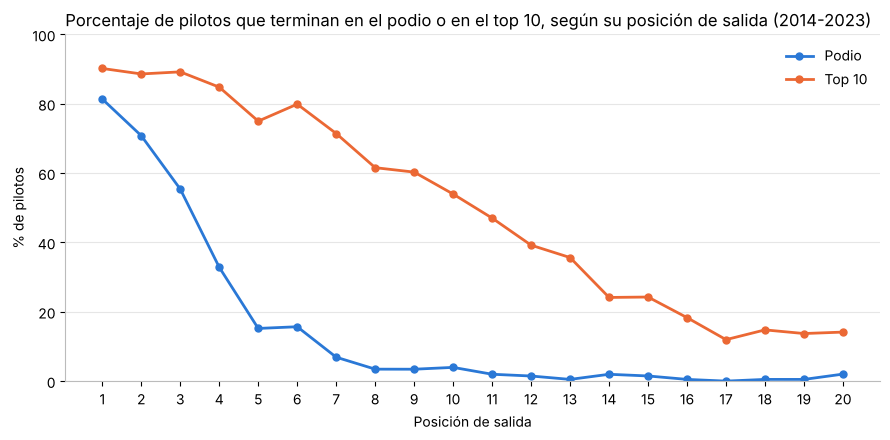

grid_adj,1,2,3,4,5,6,7,8,9,10,11,12
% podio,81,71,55,33,15,16,7,3,3,4,2,1
% top 10,90,89,89,85,75,80,71,62,60,54,47,39


In [13]:
moderno_eda = eda[eda.year >= 2014]
por_parrilla = moderno_eda[moderno_eda.grid_adj <= 20].groupby("grid_adj")[["podio", "top10"]].mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(por_parrilla.index, 100 * por_parrilla.podio, color=AZUL, lw=2, marker="o", ms=5)
ax.plot(por_parrilla.index, 100 * por_parrilla.top10, color=NARANJA, lw=2, marker="o", ms=5)
ax.set_xticks(range(1, 21))
ax.set_ylim(0, 100)
estilo(ax, "Porcentaje de pilotos que terminan en el podio o en el top 10, según su posición de salida (2014-2023)",
       "Posición de salida", "% de pilotos")
ax.legend(["Podio", "Top 10"], frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

(100 * por_parrilla.head(12)).round(0).astype(int).rename(columns={"podio": "% podio", "top10": "% top 10"}).T

**Qué nos dice.**

- Salir delante es enorme: el 81 % de los que salen en la pole terminan en el podio. Del cuarto puesto al quinto la probabilidad de podio cae a la mitad (33 % → 15 %), y desde el octavo puesto es casi nula.
- El top 10 baja de forma más suave. Salir décimo da algo más de un 50 % de puntuar, y desde atrás todavía hay un 12-15 % de opciones.
- Las curvas no llegan al 100 % ni siquiera en la pole: los abandonos y los errores hacen que nada esté garantizado.

Ahora medimos lo mismo con la métrica de la Parte 2. Antes conviene entender bien esa métrica.

#### Qué es la correlación de Spearman

**Primero, qué parte del reto usa cada métrica.** La Parte 1 (probabilidades) se evalúa con *log loss*, que veremos más adelante. La correlación de Spearman es solo para la **Parte 2** (posición). La usamos aquí porque nos permite poner nota a la parrilla como si fuera una predicción.

**La idea.** Spearman responde a una pregunta: *¿se parece el orden que he predicho al orden real?* No le importa acertar la posición exacta, sino el orden: quién va delante de quién.

- **1**: los dos órdenes son idénticos.
- **0**: no tienen ninguna relación, como si hubiéramos ordenado al azar.
- **−1**: un orden es el contrario del otro (el que predijimos primero acaba último, y así con todos).

**Cómo se calcula.** Para cada piloto se resta la posición real de la predicha; esa diferencia se llama `d`. Se elevan las diferencias al cuadrado (para que no importe el signo y para castigar más los errores grandes) y se suman. Con `n` pilotos:

$$\rho = 1 - \frac{6 \sum d^2}{n\,(n^2 - 1)}$$

No hace falta recordar la fórmula: lo importante es que **cuanto más se alejan las posiciones predichas de las reales, más baja la nota**.

**Cómo la usa el reto.** Calcula un Spearman para cada carrera de 2024 (24 en total), comparando nuestro orden con el real, y hace la media. Gana el que tenga la media más alta.

**Qué hace esta celda.** Calcula tres carreras inventadas de 5 pilotos, en las que nuestra predicción es la parrilla (A sale primero, B segundo…):

1. **Carrera tranquila**: el resultado es igual a la parrilla.
2. **Pequeños cambios**: B y C se intercambian, y también D y E.
3. **El de la pole abandona**: A sale primero y acaba último; el resto sube un puesto.

Para cada una muestra la tabla con las diferencias `d`, el cálculo a mano y el resultado de `scipy` para comprobar que coinciden.

In [14]:
prediccion = pd.Series([1, 2, 3, 4, 5], index=list("ABCDE"), name="predicha")
ejemplos = {
    "1. Carrera tranquila": [1, 2, 3, 4, 5],
    "2. Pequeños cambios": [1, 3, 2, 5, 4],
    "3. El de la pole abandona": [5, 1, 2, 3, 4],
}
for titulo, real in ejemplos.items():
    t = pd.DataFrame({"predicha": prediccion, "real": real})
    t["d"] = t.predicha - t.real
    t["d²"] = t.d ** 2
    n = len(t)
    a_mano = 1 - 6 * t["d²"].sum() / (n * (n**2 - 1))
    con_scipy = spearmanr(t.predicha, t.real).correlation
    print(f"{titulo}\n{t.T.to_string()}")
    print(f"Suma de d² = {t['d²'].sum()}  ->  Spearman = 1 - 6·{t['d²'].sum()}/({n}·{n**2 - 1}) "
          f"= {a_mano:.2f}   (scipy: {con_scipy:.2f})\n")

1. Carrera tranquila
          A  B  C  D  E
predicha  1  2  3  4  5
real      1  2  3  4  5
d         0  0  0  0  0
d²        0  0  0  0  0
Suma de d² = 0  ->  Spearman = 1 - 6·0/(5·24) = 1.00   (scipy: 1.00)

2. Pequeños cambios
          A  B  C  D  E
predicha  1  2  3  4  5
real      1  3  2  5  4
d         0 -1  1 -1  1
d²        0  1  1  1  1
Suma de d² = 4  ->  Spearman = 1 - 6·4/(5·24) = 0.80   (scipy: 0.80)

3. El de la pole abandona
           A  B  C  D  E
predicha   1  2  3  4  5
real       5  1  2  3  4
d         -4  1  1  1  1
d²        16  1  1  1  1
Suma de d² = 20  ->  Spearman = 1 - 6·20/(5·24) = 0.00   (scipy: 0.00)



**Qué nos dicen los ejemplos.**

- **Carrera tranquila (1,0).** Ningún error: orden perfecto.
- **Pequeños cambios (0,8).** Fallamos cuatro de cinco posiciones, pero solo por un puesto cada una. El orden general se mantiene y la nota sigue siendo alta. Spearman perdona los errores pequeños.
- **El de la pole abandona (0,0).** Acertamos el orden relativo de B, C, D y E, pero un solo error de cuatro puestos (que al cuadrado pesa 16) hunde la nota hasta cero. Spearman castiga mucho los errores grandes.

El tercer caso es justo lo que pasa con los abandonos. Por eso el Spearman de la parrilla no llega a 1 en las carreras reales, y por eso vimos que antes de los 2000, con muchos más abandonos, era más bajo.

**Consecuencia para el modelo.** Para mejorar a la parrilla hay que acertar en los casos en los que el resultado se aleja de ella: pilotos rápidos que salen atrás por una penalización (remontarán), coches poco fiables (pueden abandonar) o circuitos donde se adelanta mucho.

#### Spearman de la parrilla en las carreras reales

**Qué hace esta celda.** Calcula, para cada carrera desde 1980, la correlación de Spearman entre la parrilla y el resultado final, y dibuja la media de cada temporada. Es exactamente la puntuación que obtendría en la Parte 2 un modelo que predijera "cada uno termina donde sale".

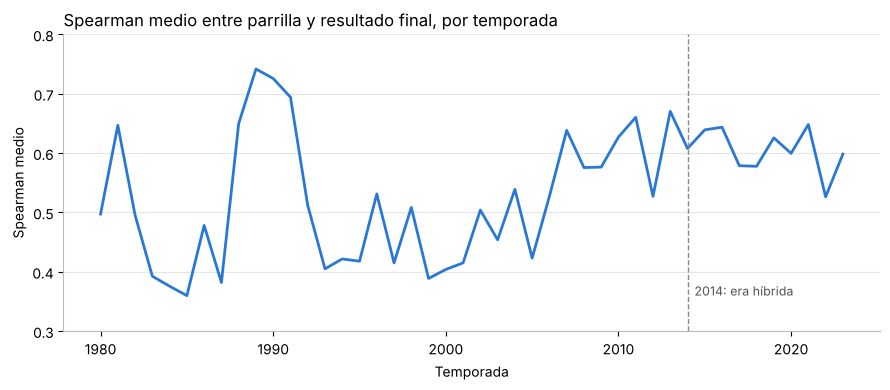

Spearman medio 2014-2023: 0.604
Spearman medio 2023:      0.598


In [15]:
def spearman_parrilla(g):
    return spearmanr(g.grid_adj, g.positionOrder).correlation


sp_carrera = (eda[eda.year >= 1980].groupby(["year", "raceId"]).apply(spearman_parrilla)
              .rename("spearman").reset_index())
sp_anual = sp_carrera.groupby("year").spearman.mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sp_anual.index, sp_anual.values, color=AZUL, lw=2)
ax.axvline(2014, color=GRIS, lw=1, ls="--")
ax.text(2014.4, 0.36, "2014: era híbrida", color="#555555", fontsize=9)
ax.set_ylim(0.3, 0.8)
estilo(ax, "Spearman medio entre parrilla y resultado final, por temporada", "Temporada", "Spearman medio")
plt.tight_layout()
plt.show()

print("Spearman medio 2014-2023:", round(sp_carrera[sp_carrera.year >= 2014].spearman.mean(), 3))
print("Spearman medio 2023:     ", round(sp_anual.loc[2023], 3))

**Qué nos dice.** Desde 2014 la parrilla sola consigue un Spearman medio de alrededor de 0,6 cada año (0,60 en 2023). Es la cifra que hay que superar en la Parte 2. Se ve en el gráfico que antes de 2005 el valor era más bajo y más irregular: había muchos más abandonos, que desordenan el resultado. Lo vemos en el siguiente apartado.

### 4.2 ¿Cómo cambia la tasa de abandonos entre épocas?

**Qué hace esta celda.** Calcula, para cada temporada desde 1950, el porcentaje de pilotos que no terminaron la carrera, separando los abandonos mecánicos (averías) de los accidentes y otros motivos. Usa las columnas `abandono_mecanico` y `abandono_accidente` que creamos en la sección 2.3.

**Por qué.** Si el comportamiento de las carreras ha cambiado mucho con los años, entrenar con todo el histórico enseñaría al modelo patrones que ya no se dan. Los abandonos son el ejemplo más claro.

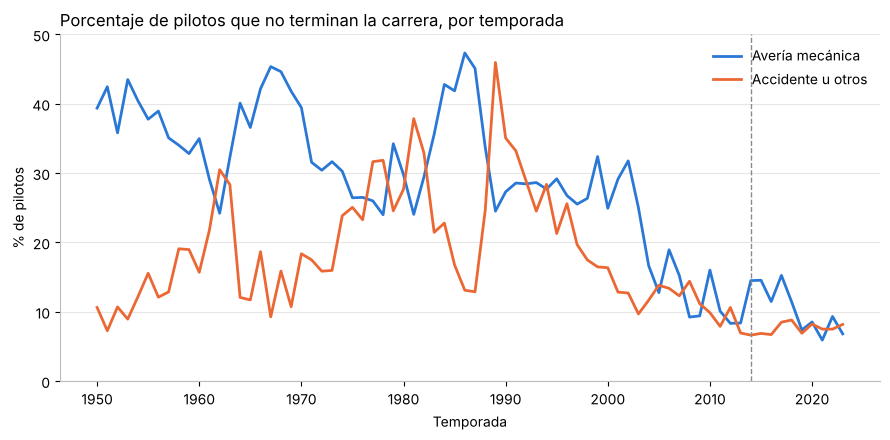

,mecanico,accidente,total
year,,,
1960,35.0,15.7,50.7
1980,29.8,27.7,57.4
2000,24.9,16.4,41.3
2010,16.0,9.9,25.9
2014,14.5,6.6,21.1
2017,15.2,8.5,23.8
2020,8.5,8.2,16.8
2023,6.8,8.2,15.0


In [16]:
abandonos = eda.groupby("year").agg(
    mecanico=("abandono_mecanico", "mean"),
    accidente=("abandono_accidente", "mean"),
)
abandonos["total"] = abandonos.mecanico + abandonos.accidente

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(abandonos.index, 100 * abandonos.mecanico, color=AZUL, lw=2, label="Avería mecánica")
ax.plot(abandonos.index, 100 * abandonos.accidente, color=NARANJA, lw=2, label="Accidente u otros")
ax.axvline(2014, color=GRIS, lw=1, ls="--")
ax.set_ylim(0, 50)
estilo(ax, "Porcentaje de pilotos que no terminan la carrera, por temporada", "Temporada", "% de pilotos")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

(100 * abandonos.loc[[1960, 1980, 2000, 2010, 2014, 2017, 2020, 2023]]).round(1)

**Qué nos dice.**

- Hasta los años noventa abandonaba la mitad de la parrilla o más, sobre todo por averías. Hoy terminan más de ocho de cada diez.
- En 2014 hay un repunte de averías (14,5 %): ese año llegaron los motores híbridos, que al principio fallaban mucho. Desde entonces la fiabilidad mejora y las averías bajan a un 6-9 % en 2021-2023.
- Los accidentes se mantienen bastante estables, en torno al 7-8 %.

**Consecuencia para el modelo.** Las carreras de hace décadas no se parecen a las actuales. Además, la fiabilidad cambia de un año a otro, así que conviene medirla con datos recientes de cada coche (lo haremos en la ingeniería de variables).

### 4.3 ¿Qué circuitos permiten adelantar y cuáles no?

**Qué hace esta celda.** Para cada circuito con al menos 4 carreras entre 2014 y 2023, calcula el Spearman medio entre parrilla y resultado. Un valor alto indica que el resultado se parece mucho a la parrilla, es decir, que se adelanta poco. Un valor bajo indica que la carrera cambia mucho el orden.

Hacemos el cálculo de dos formas:

- **Con todos los pilotos**, que es lo que mide el reto.
- **Solo con los que terminan**, para separar los adelantamientos de los abandonos. Un circuito puede tener un Spearman bajo simplemente porque en él hay muchos accidentes.

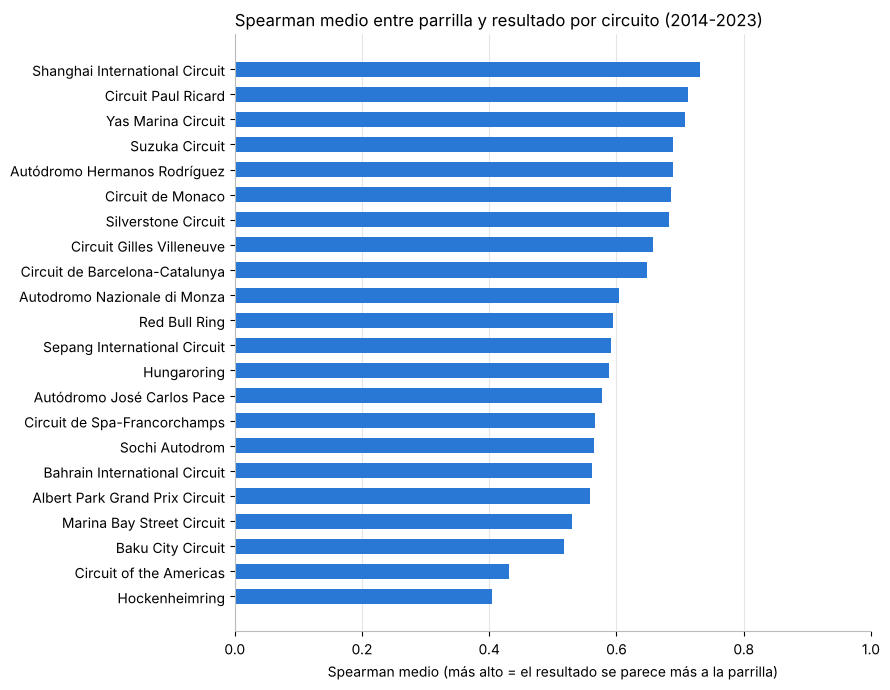

,name,carreras,todos,terminados
circuitId,,,,
10,Hockenheimring,4,0.40,0.53
69,Circuit of the Americas,9,0.43,0.74
73,Baku City Circuit,7,0.52,0.81
15,Marina Bay Street Circuit,8,0.53,0.79
1,Albert Park Grand Prix Circuit,8,0.56,0.81
3,Bahrain International Circuit,11,0.56,0.79
71,Sochi Autodrom,8,0.56,0.70
13,Circuit de Spa-Francorchamps,10,0.57,0.75
18,Autódromo José Carlos Pace,9,0.58,0.73


In [17]:
def spearman_terminados(g):
    g = g[g.terminado]
    return spearmanr(g.grid_adj, g.positionOrder).correlation if len(g) > 5 else np.nan


circ = moderno_eda.groupby(["circuitId", "raceId"]).agg(
    todos=("grid_adj", lambda s: spearman_parrilla(moderno_eda.loc[s.index])),
    terminados=("grid_adj", lambda s: spearman_terminados(moderno_eda.loc[s.index])),
).reset_index()
circ_resumen = (circ.groupby("circuitId")
                .agg(carreras=("raceId", "size"), todos=("todos", "mean"), terminados=("terminados", "mean"))
                .query("carreras >= 4")
                .join(tablas["circuits"].set_index("circuitId")["name"])
                .sort_values("todos"))

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(circ_resumen.name, circ_resumen.todos, color=AZUL, height=0.6)
ax.set_xlim(0, 1)
estilo(ax, "Spearman medio entre parrilla y resultado por circuito (2014-2023)",
       "Spearman medio (más alto = el resultado se parece más a la parrilla)")
ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

circ_resumen[["name", "carreras", "todos", "terminados"]].round(2)

**Qué nos dice.**

- Hay diferencias claras entre circuitos: desde alrededor de 0,4 (Hockenheim, Austin) hasta más de 0,7 (Shanghái, Paul Ricard, Abu Dabi). En los primeros la parrilla predice bastante peor.
- La columna `terminados` cambia bastante la foto. Austin sube de 0,43 a 0,74 y los urbanos Bakú y Singapur, de algo más de 0,5 a alrededor de 0,8: buena parte de su desorden viene de abandonos y accidentes, no de adelantamientos.
- Mirando solo a los que terminan, Mónaco es el circuito donde el resultado más se parece a la parrilla (0,86), lo que encaja con su fama de que no se puede adelantar. Con todos los pilotos queda algo más abajo porque los accidentes también desordenan.
- Hockenheim es el más bajo en las dos versiones, pero solo tiene 4 carreras y el dato es poco fiable.

**Consecuencia para el modelo.** El circuito modifica cuánto pesa la parrilla. Crearemos una variable con el "Spearman histórico" de cada circuito, calculada solo con carreras anteriores, para que el modelo sepa si en ese circuito la parrilla manda mucho o poco.

### 4.4 ¿Cuánto domina cada equipo según la temporada?

**Qué hace esta celda.**

1. Para cada temporada desde 2014, busca el equipo con más victorias y calcula qué porcentaje de carreras ganó y qué porcentaje de podios consiguió.
2. Calcula cuánto se parece el nivel de los equipos de un año al del año anterior. Para cada equipo y temporada se toma su posición final media; después se calcula la correlación entre la temporada y la anterior. Un valor cercano a 1 significa que el orden de los equipos se mantiene.

**Por qué.** En F1 el coche pesa mucho. Si un equipo gana casi todo durante años, las variables del equipo serán muy predictivas. Y si el nivel cambia poco de un año a otro, la forma de la temporada anterior sirve para empezar la siguiente.

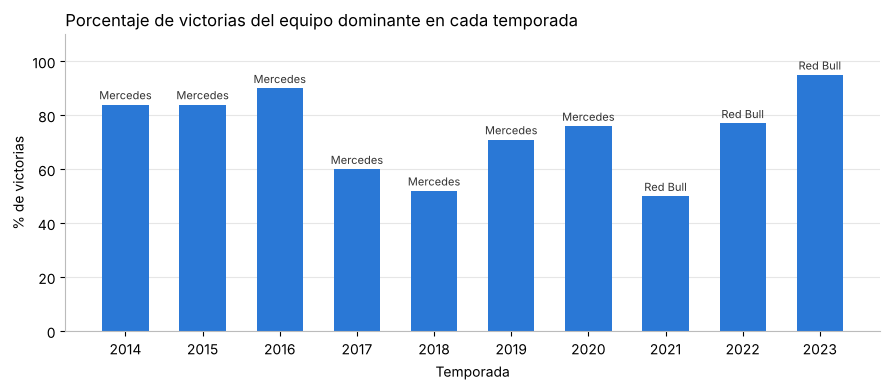

,equipo dominante,% victorias,% podios,corr. con año anterior
temporada,,,,
2014,mercedes,84,54,NaN
2015,mercedes,84,56,0.72
2016,mercedes,90,52,0.90
2017,mercedes,60,43,0.92
2018,mercedes,52,40,0.87
2019,mercedes,71,51,0.92
2020,mercedes,76,49,0.83
2021,red_bull,50,35,0.92
2022,red_bull,77,42,0.91


In [18]:
dominio = []
for year, g in moderno_eda.groupby("year"):
    ganadores = g[g.positionOrder == 1].constructorRef.value_counts()
    podios = g[g.podio == 1].constructorRef.value_counts()
    eq = ganadores.index[0]
    dominio.append({"temporada": year, "equipo dominante": eq,
                    "% victorias": round(100 * ganadores.iloc[0] / ganadores.sum()),
                    "% podios": round(100 * podios.get(eq, 0) / podios.sum())})
dominio = pd.DataFrame(dominio).set_index("temporada")

nivel = moderno_eda.groupby(["year", "constructorRef"]).positionOrder.mean().unstack()
dominio["corr. con año anterior"] = [np.nan] + [round(nivel.loc[y].corr(nivel.loc[y - 1]), 2)
                                                for y in nivel.index[1:]]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(dominio.index, dominio["% victorias"], color=AZUL, width=0.6)
for y, row in dominio.iterrows():
    ax.text(y, row["% victorias"] + 2, row["equipo dominante"].replace("_", " ").title(),
            ha="center", fontsize=8, color="#333333")
ax.set_ylim(0, 110)
ax.set_xticks(dominio.index)
estilo(ax, "Porcentaje de victorias del equipo dominante en cada temporada", "Temporada", "% de victorias")
plt.tight_layout()
plt.show()

dominio

**Qué nos dice.**

- Mercedes ganó entre el 52 % y el 90 % de las carreras cada año de 2014 a 2020. Red Bull tomó el relevo desde 2021 y en 2023 ganó el 95 % (21 de 22).
- El orden de los equipos se mantiene mucho de un año a otro: la correlación es de 0,83 a 0,93 casi todos los años. La más baja (0,72) es 2015, el segundo año del cambio de motores.
- Aun así, hay equipos que suben o bajan entre temporadas. Al principio de cada año, la forma del año anterior es una pista útil pero imperfecta.

**Consecuencia para el modelo.** Necesitamos variables del equipo (forma reciente, mundial de constructores) además de las del piloto. Y conviene que la forma reciente pese más que la histórica, para captar cuanto antes los cambios de nivel dentro de una temporada.

### 4.5 Decisión: desde qué año entrenar

El reto pide justificar el periodo de entrenamiento. Con lo que hemos visto:

| Argumento | Qué hemos visto |
|---|---|
| Abandonos | Antes de los 2000 abandonaba la mitad de la parrilla; desde 2014, entre un 13 % y un 24 %. |
| Parrilla | Desde 2014 el Spearman parrilla-resultado es estable, en torno a 0,6. |
| Reglamento | 2014 inicia la era de los motores híbridos, la misma que en 2024. |
| Puntos | El sistema que premia a los 10 primeros existe desde 2010, así que `top10` significa "puntuar" en todo el periodo. |
| Cantidad de datos | 2014-2023 son 10 temporadas y unas 4.100 filas: suficientes para los modelos que usaremos. |

**Decisión: entrenar con las temporadas 2014 a 2023.** Para elegir el modelo y sus hiperparámetros usaremos 2023 como validación: entrenaremos con 2014-2022 y mediremos en 2023, que es lo más parecido a 2024 que tenemos.

Hay un matiz: las variables de "historial" (forma reciente, historial en el circuito) sí pueden usar carreras anteriores a 2014. Un piloto que corrió en 2013 tiene una forma reciente al empezar 2014. Lo que limitamos a 2014-2023 son las **filas** con las que aprende el modelo, no la información histórica disponible para construir variables.

En 2022 cambió el reglamento técnico (nuevos coches de efecto suelo). El Spearman de ese año fue algo más bajo (0,53), pero el orden de los equipos se mantuvo (correlación 0,91 con 2021). No justifica empezar en 2022 y quedarnos con solo dos temporadas. Si en la validación vemos que conviene, probaremos a dar más peso a los años recientes.

## 5. Ingeniería de variables

**Qué es.** Un modelo no entiende frases como "Verstappen viene de ganar cinco carreras seguidas". Solo entiende columnas de números. La ingeniería de variables consiste en traducir lo que sabemos antes de la carrera a columnas numéricas. A cada una de esas columnas la llamamos **variable** (en inglés, *feature*).

**Las dos familias de variables.**

1. **Del fin de semana**: lo que pasó el sábado (clasificación, parrilla, sprint). Se puede usar directamente.
2. **Históricas**: resúmenes de carreras **anteriores** (forma reciente, mundial, fiabilidad, historial en el circuito). Aquí está el riesgo de fuga de información, y hay que construirlas con cuidado.

**La técnica clave: `shift(1)`.** Para calcular, por ejemplo, la posición media de un piloto en sus últimas 5 carreras *antes* de la actual, ordenamos sus carreras en el tiempo y desplazamos la columna una fila hacia abajo. Así, en la fila de cada carrera queda el dato de la carrera anterior, nunca el de la propia. Con un piloto que ha terminado 3.º, 1.º, 5.º y 2.º:

| Carrera | `positionOrder` | `shift(1)` | media de las 2 anteriores |
|---|---|---|---|
| 1 | 3 | (vacío) | (vacío) |
| 2 | 1 | 3 | 3,0 |
| 3 | 5 | 1 | 2,0 |
| 4 | 2 | 5 | 3,0 |

En la carrera 4 la media es 3,0, calculada con las carreras 2 y 3. El 2.º puesto de la carrera 4 no interviene. Sin `shift(1)`, la media incluiría el resultado que queremos predecir.

**Cómo está organizada esta sección.** Cada bloque de variables es una función (`añadir_...`) que recibe la tabla y le añade columnas. Las aplicamos una detrás de otra. Organizarlo así permite, al final, repetir todo el proceso con datos modificados para comprobar automáticamente que no hay fugas (sección 5.9).

### 5.1 Tabla de trabajo

**Qué hace esta celda.** Prepara la tabla de partida, `df`, con todas las carreras desde 1950. Usamos todo el histórico aunque solo entrenemos con 2014-2023, porque las variables históricas de 2014 necesitan saber qué pasó en 2013 y antes.

Añade tres cosas:

1. **`grid_adj` y `pit_lane`.** La parrilla corregida (`grid = 0` pasa a ser "último + 1") y una marca de 0/1 que indica si el piloto sale desde boxes.
2. **`n_coches`.** Cuántos coches toman parte en la carrera. Se conoce de antemano y ayuda a interpretar las posiciones.
3. **`equipo`.** Varios equipos han cambiado de nombre sin cambiar de fábrica ni de personal. Por ejemplo, Force India pasó a llamarse Racing Point y después Aston Martin; Toro Rosso pasó a AlphaTauri y después a RB. Para el dataset son equipos distintos, así que al estrenar nombre su historial empezaría vacío. Agrupamos cada linaje bajo un mismo nombre para que la forma del equipo no se pierda con el cambio.

In [19]:
LINAJE = {
    "force_india": "aston_martin", "racing_point": "aston_martin", "aston_martin": "aston_martin",
    "toro_rosso": "rb", "alphatauri": "rb", "rb": "rb",
    "renault": "alpine", "lotus_f1": "alpine", "alpine": "alpine",
    "sauber": "sauber", "alfa": "sauber",
    "virgin": "manor", "marussia": "manor", "manor": "manor",
    "lotus_racing": "caterham", "caterham": "caterham",
}

df = base.sort_values(["race_idx", "positionOrder"]).reset_index(drop=True).copy()
df["equipo"] = df.constructorRef.map(LINAJE).fillna(df.constructorRef)
df["pit_lane"] = (df.grid == 0).astype(int)
df["grid_adj"] = df.grid.where(df.grid > 0, df.groupby("raceId").grid.transform("max") + 1)
df["n_coches"] = df.groupby("raceId").driverId.transform("size")

print(df[df.year >= 2014].groupby("equipo").year.agg(["min", "max"]).sort_values("min"))

               min   max
equipo                  
alpine        2014  2024
aston_martin  2014  2024
caterham      2014  2014
ferrari       2014  2024
manor         2014  2016
mclaren       2014  2024
mercedes      2014  2024
rb            2014  2024
sauber        2014  2024
red_bull      2014  2024
williams      2014  2024
haas          2016  2024


**Qué mirar en la salida.** Desde 2014 quedan los equipos agrupados por linaje: por ejemplo, `aston_martin` aparece de 2014 a 2024 aunque en ese periodo se llamó de tres formas distintas.

### 5.2 Variables del fin de semana

Todo lo de este bloque ocurre el sábado o antes, así que se puede usar directamente para la carrera.

**Qué hace esta celda.** Crea:

| Variable | Qué mide |
|---|---|
| `quali_pos` | posición en la clasificación |
| `gap_pole_pct` | distancia a la pole en % (sección 2.5). Se limita a un máximo de 10 % para que un piloto que apenas rodó no distorsione el modelo |
| `penalizacion` | `grid_adj − quali_pos`. Positiva si sale más atrás de lo que clasificó (penalización); un piloto rápido que sale atrás suele remontar |
| `gap_companero` | `gap_pole_pct` del piloto menos el de su compañero. Negativo si fue más rápido que él. Compara a dos pilotos con el mismo coche, así que mide al piloto, no al coche |
| `sprint_pos` | posición en la sprint de ese fin de semana (vacío si no hubo sprint) |

Para encontrar al compañero se agrupa por carrera y equipo: con dos coches por equipo, el dato del compañero es la suma del grupo menos el propio.

In [20]:
def añadir_fin_de_semana(df):
    q = tablas["qualifying"][["raceId", "driverId", "position", "gap_pole_pct"]].rename(
        columns={"position": "quali_pos"})
    df = df.merge(q, on=["raceId", "driverId"], how="left")
    # Sin registro de clasificación (pocos casos): se usa la parrilla
    df["quali_pos"] = df.quali_pos.fillna(df.grid_adj)
    df["gap_pole_pct"] = df.gap_pole_pct.clip(upper=10)
    df["penalizacion"] = df.grid_adj - df.quali_pos

    # Compañero de equipo: misma carrera y mismo equipo
    grupo = df.groupby(["raceId", "equipo"]).gap_pole_pct
    n_grupo = grupo.transform("count")
    gap_companero = (grupo.transform("sum") - df.gap_pole_pct) / (n_grupo - 1)
    df["gap_companero"] = (df.gap_pole_pct - gap_companero).where(n_grupo == 2)

    sp = tablas["sprint_results"][["raceId", "driverId", "positionOrder"]].rename(
        columns={"positionOrder": "sprint_pos"})
    df = df.merge(sp, on=["raceId", "driverId"], how="left")
    return df


df = añadir_fin_de_semana(df)
df.loc[(df.year == 2023) & (df["round"] == 1), ["name", "driverRef", "grid_adj", "quali_pos", "penalizacion",
                         "gap_pole_pct", "gap_companero", "sprint_pos"]].sort_values("grid_adj").head(6).round(3)

,name,driverRef,grid_adj,quali_pos,penalizacion,gap_pole_pct,gap_companero,sprint_pos
25840,Bahrain Grand Prix,max_verstappen,1,1.0,0.0,0.000,-0.154,NaN
25841,Bahrain Grand Prix,perez,2,2.0,0.0,0.154,0.154,NaN
25858,Bahrain Grand Prix,leclerc,3,3.0,0.0,0.326,-0.172,NaN
25843,Bahrain Grand Prix,sainz,4,4.0,0.0,0.497,0.172,NaN
25842,Bahrain Grand Prix,alonso,5,5.0,0.0,0.700,-0.557,NaN
25846,Bahrain Grand Prix,russell,6,6.0,0.0,0.705,-0.049,NaN


**Qué mirar en la salida.** Los seis primeros de la parrilla de Baréin 2023, la primera carrera de esa temporada. El de la pole tiene `gap_pole_pct = 0`. `gap_companero` negativo indica que el piloto fue más rápido que su compañero. `sprint_pos` está vacío porque en Baréin no hubo sprint.

### 5.3 Forma reciente del piloto

**Qué hace esta celda.** Define la función auxiliar `media_previa`, que aplica la técnica del `shift(1)` explicada al principio: para cada piloto (o equipo), ordena sus carreras en el tiempo y calcula la media de las últimas `n` **anteriores**. Con ella crea:

| Variable | Qué mide |
|---|---|
| `piloto_pos_5`, `piloto_pos_10` | posición final media en las últimas 5 y 10 carreras |
| `piloto_puntos_5` | puntos medios en las últimas 5 carreras |
| `piloto_top10_10`, `piloto_podio_10` | proporción de veces en el top 10 y en el podio en las últimas 10 |
| `piloto_parrilla_5` | posición de salida media en las últimas 5: su ritmo a una vuelta |
| `piloto_remonta_10` | puestos ganados de media en las últimas 10 (`grid_adj − positionOrder`): si suele mejorar en carrera |
| `piloto_abandonos_10` | proporción de abandonos en las últimas 10 |
| `piloto_experiencia` | número de Grandes Premios disputados antes de este |

**Por qué dos ventanas (5 y 10).** La de 5 reacciona rápido a los cambios de forma; la de 10 es más estable y menos sensible a una mala carrera aislada. Dejamos que el modelo decida cuánto pesa cada una.

Las columnas `positionOrder`, `points`, `terminado`… están en la lista de prohibidas, pero aquí se usan **de carreras anteriores** gracias al `shift(1)`. Eso está permitido.

In [21]:
def media_previa(df, grupo, col, n):
    """Media de `col` en las últimas `n` carreras ANTERIORES de cada `grupo`."""
    return df.groupby(grupo)[col].transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())


def añadir_forma_piloto(df):
    df = df.sort_values(["race_idx", "driverId"]).reset_index(drop=True)
    df["_remonta"] = df.grid_adj - df.positionOrder
    df["_abandono"] = (~df.terminado).astype(float)
    df["piloto_pos_5"] = media_previa(df, "driverId", "positionOrder", 5)
    df["piloto_pos_10"] = media_previa(df, "driverId", "positionOrder", 10)
    df["piloto_puntos_5"] = media_previa(df, "driverId", "points", 5)
    df["piloto_top10_10"] = media_previa(df, "driverId", "top10", 10)
    df["piloto_podio_10"] = media_previa(df, "driverId", "podio", 10)
    df["piloto_parrilla_5"] = media_previa(df, "driverId", "grid_adj", 5)
    df["piloto_remonta_10"] = media_previa(df, "driverId", "_remonta", 10)
    df["piloto_abandonos_10"] = media_previa(df, "driverId", "_abandono", 10)
    df["piloto_experiencia"] = df.groupby("driverId").cumcount()  # carreras previas
    return df.drop(columns=["_remonta", "_abandono"])


df = añadir_forma_piloto(df)

**Comprobación a mano.** Para estar seguros de que la variable hace lo que decimos, tomamos un piloto y una carrera y la recalculamos a mano: mostramos sus 5 carreras anteriores y su media, y la comparamos con el valor de `piloto_pos_5` en esa carrera.

**Qué hace esta celda.** Busca a Fernando Alonso en el GP de Mónaco 2023, lista sus cinco carreras anteriores con su posición final y comprueba que la media coincide con `piloto_pos_5`.

In [22]:
alonso = df[df.driverRef == "alonso"].sort_values("race_idx")
fila = alonso[(alonso.year == 2023) & (alonso.name == "Monaco Grand Prix")].iloc[0]
anteriores = alonso[alonso.race_idx < fila.race_idx].tail(5)

print("Carrera que queremos predecir: GP de Mónaco 2023 (Fernando Alonso)\n")
print("Sus 5 carreras anteriores y la posición en que terminó cada una:")
print(anteriores[["year", "round", "name", "positionOrder"]]
      .rename(columns={"year": "año", "round": "ronda", "name": "carrera", "positionOrder": "posición final"})
      .to_string(index=False))

posiciones = anteriores.positionOrder.tolist()
suma = sum(posiciones)
print(f"\nMedia a mano: ({' + '.join(map(str, posiciones))}) / 5 = {suma} / 5 = {suma / 5:.2f}")
print(f"Valor de piloto_pos_5 que el notebook ha guardado en la fila de Mónaco 2023: {fila.piloto_pos_5:.2f}")
print(f"\nLo que pasó en Mónaco: terminó {fila.positionOrder}.º. Ese resultado no entra en la media,")
print("porque el sábado por la noche todavía no se conocía.")

Carrera que queremos predecir: GP de Mónaco 2023 (Fernando Alonso)

Sus 5 carreras anteriores y la posición en que terminó cada una:
 año  ronda                  carrera  posición final
2023      1       Bahrain Grand Prix               3
2023      2 Saudi Arabian Grand Prix               3
2023      3    Australian Grand Prix               3
2023      4    Azerbaijan Grand Prix               4
2023      5         Miami Grand Prix               3

Media a mano: (3 + 3 + 3 + 4 + 3) / 5 = 16 / 5 = 3.20
Valor de piloto_pos_5 que el notebook ha guardado en la fila de Mónaco 2023: 3.20

Lo que pasó en Mónaco: terminó 2.º. Ese resultado no entra en la media,
porque el sábado por la noche todavía no se conocía.


**Cómo leer la salida.**

1. La tabla muestra las cinco carreras que Alonso disputó justo **antes** de Mónaco 2023 (las rondas 1 a 5 de esa temporada) y en qué posición terminó cada una.
2. La media de esas cinco posiciones, calculada a mano, es 3,2.
3. El notebook ha guardado ese mismo 3,2 en la variable `piloto_pos_5` de la fila de Mónaco 2023. Coinciden, así que la función hace lo que queremos.
4. En Mónaco Alonso terminó 2.º, y ese 2 no aparece en la media. Si apareciera, la variable estaría usando el resultado de la carrera que queremos predecir: sería una fuga de información.

Dicho de otra forma: lo que el modelo "sabe" de Alonso al predecir Mónaco es que en las cinco carreras anteriores terminó, de media, en la posición 3,2. Es la información que tendría un analista el sábado por la noche.

### 5.4 Forma y fiabilidad del equipo

El EDA mostró que el coche pesa mucho. Aquí medimos al **equipo** con sus dos coches juntos.

**Qué hace esta celda.**

1. Resume cada carrera a nivel de equipo: posición media de sus dos coches, puntos totales y proporción de abandonos por avería (`abandono_mecanico`).
2. Sobre esa tabla aplica `media_previa` por equipo, igual que con los pilotos.
3. Une el resultado a cada piloto según su equipo y carrera.

| Variable | Qué mide |
|---|---|
| `equipo_pos_5` | posición media de sus coches en las últimas 5 carreras |
| `equipo_puntos_5` | puntos medios por carrera en las últimas 5 |
| `equipo_averias_10` | proporción de coches del equipo que abandonaron por avería en las últimas 10 carreras: la **fiabilidad** |

**Por qué separar averías de accidentes.** Una avería dice algo del coche y tiende a repetirse; un accidente depende más de las circunstancias de cada carrera.

In [23]:
def añadir_forma_equipo(df):
    eq = (df.groupby(["raceId", "race_idx", "equipo"])
          .agg(_pos=("positionOrder", "mean"), _puntos=("points", "sum"),
               _averias=("abandono_mecanico", "mean"))
          .reset_index().sort_values("race_idx"))
    eq["equipo_pos_5"] = media_previa(eq, "equipo", "_pos", 5)
    eq["equipo_puntos_5"] = media_previa(eq, "equipo", "_puntos", 5)
    eq["equipo_averias_10"] = media_previa(eq, "equipo", "_averias", 10)
    cols = ["raceId", "equipo", "equipo_pos_5", "equipo_puntos_5", "equipo_averias_10"]
    return df.merge(eq[cols], on=["raceId", "equipo"], how="left")


df = añadir_forma_equipo(df)

### 5.5 Mundial antes de la carrera

Como vimos en la sección 2.7, la fila de una carrera en `driver_standings` es el mundial **después** de esa carrera. Para cada carrera hay que tomar la fila de la **anterior de la misma temporada**.

**Qué hace esta celda.**

1. Crea `previa`, una tabla que asocia a cada carrera el `raceId` de la carrera anterior del mismo año. En la ronda 1 no hay anterior.
2. Une el mundial de pilotos y el de constructores de esa carrera anterior.
3. Rellena con 0 los puntos y las victorias cuando no hay dato (ronda 1, o un piloto que debuta a mitad de año). La posición en el mundial se deja vacía en esos casos, porque no existe.
4. Añade `mundial_piloto_pct_lider`: los puntos del piloto divididos por los del líder. Tener 100 puntos no significa lo mismo en la ronda 5 que en la 20; el porcentaje sí es comparable.

| Variable | Qué mide |
|---|---|
| `mundial_piloto_pts`, `mundial_piloto_pos`, `mundial_piloto_victorias` | puntos, posición y victorias del piloto en el mundial antes de la carrera |
| `mundial_piloto_pct_lider` | puntos del piloto en proporción a los del líder |
| `mundial_equipo_pts`, `mundial_equipo_pos` | puntos y posición del equipo en el mundial de constructores antes de la carrera |

In [24]:
def añadir_mundial(df):
    previa = races.sort_values("race_idx")[["raceId", "year"]].copy()
    previa["raceId_previa"] = previa.groupby("year").raceId.shift(1)
    df = df.merge(previa[["raceId", "raceId_previa"]], on="raceId", how="left")

    dsp = tablas["driver_standings"][["raceId", "driverId", "points", "position", "wins"]].rename(columns={
        "raceId": "raceId_previa", "points": "mundial_piloto_pts",
        "position": "mundial_piloto_pos", "wins": "mundial_piloto_victorias"})
    csp = tablas["constructor_standings"][["raceId", "constructorId", "points", "position"]].rename(columns={
        "raceId": "raceId_previa", "points": "mundial_equipo_pts", "position": "mundial_equipo_pos"})
    df = df.merge(dsp, on=["raceId_previa", "driverId"], how="left")
    df = df.merge(csp, on=["raceId_previa", "constructorId"], how="left")

    for c in ["mundial_piloto_pts", "mundial_piloto_victorias", "mundial_equipo_pts"]:
        df[c] = df[c].fillna(0)
    lider = df.groupby("raceId").mundial_piloto_pts.transform("max")
    df["mundial_piloto_pct_lider"] = np.where(lider > 0, df.mundial_piloto_pts / lider, 0)
    return df.drop(columns="raceId_previa")


df = añadir_mundial(df)

# Comprobación: en la ronda 1 de cada temporada nadie puede tener puntos
print("Puntos de mundial en rondas 1 (debe ser 0):", df.loc[df["round"] == 1, "mundial_piloto_pts"].sum())
df.loc[(df.year == 2023) & (df["round"] == 2),
       ["name", "driverRef", "mundial_piloto_pts", "mundial_piloto_pos", "mundial_equipo_pts"]].sort_values("mundial_piloto_pos").head(5)

Puntos de mundial en rondas 1 (debe ser 0): 0.0


,name,driverRef,mundial_piloto_pts,mundial_piloto_pos,mundial_equipo_pts
25866,Saudi Arabian Grand Prix,max_verstappen,25.0,1.0,43.0
25863,Saudi Arabian Grand Prix,perez,18.0,2.0,43.0
25861,Saudi Arabian Grand Prix,alonso,15.0,3.0,23.0
25867,Saudi Arabian Grand Prix,sainz,12.0,4.0,12.0
25860,Saudi Arabian Grand Prix,hamilton,10.0,5.0,16.0


**Qué mirar en la salida.** La suma de puntos en las rondas 1 es 0: nadie llega a la primera carrera con puntos. En la ronda 2 de 2023 (Arabia Saudí), Verstappen llega con 25 puntos, Pérez con 18 y Alonso con 15: exactamente lo que ganaron en Baréin, la carrera anterior. Es justo lo que se sabía el sábado antes de esa carrera.

### 5.6 Duelo con el compañero de equipo

Ya tenemos la diferencia de clasificación con el compañero en este fin de semana (`gap_companero`). Ahora añadimos la historia reciente del duelo.

**Qué hace esta celda.** En cada carrera anterior en la que los dos compañeros corrieron, marca con 1 al piloto que terminó delante y con 0 al otro. Después calcula la proporción de duelos ganados en las últimas 10 carreras: `companero_duelos_10`. Un 0,8 significa que terminó por delante de su compañero en 8 de cada 10 carreras.

**Por qué.** El compañero tiene el mismo coche. Ganarle con frecuencia es la mejor medida disponible de la calidad del piloto, separada de la del coche.

In [25]:
def añadir_duelo_companero(df):
    df = df.sort_values(["race_idx", "driverId"]).reset_index(drop=True)
    grupo = df.groupby(["raceId", "equipo"]).positionOrder
    n_grupo = grupo.transform("count")
    pos_companero = grupo.transform("sum") - df.positionOrder
    df["_gana_duelo"] = (df.positionOrder < pos_companero).astype(float).where(n_grupo == 2)
    df["companero_duelos_10"] = df.groupby("driverId")._gana_duelo.transform(
        lambda s: s.shift(1).rolling(10, min_periods=1).mean())
    return df.drop(columns="_gana_duelo")


df = añadir_duelo_companero(df)

### 5.7 Historial en el circuito

**Qué hace esta celda.** Crea tres variables relacionadas con el circuito:

| Variable | Qué mide |
|---|---|
| `piloto_circuito_pos` | posición media del piloto en sus últimas 5 visitas a este circuito |
| `piloto_circuito_visitas` | cuántas veces ha corrido antes en este circuito |
| `circuito_spearman` | Spearman medio entre parrilla y resultado en las carreras anteriores de este circuito (desde 2000). Le dice al modelo si en este circuito la parrilla manda mucho o poco, como vimos en el EDA |

Para `circuito_spearman` se calcula primero un Spearman por carrera y después la media de las anteriores en el mismo circuito, con el mismo `shift(1)`. Si el circuito es nuevo y no tiene historial (como Las Vegas o Miami en su primer año), se usa la media de todas las carreras anteriores.

In [26]:
def añadir_circuito(df):
    df = df.sort_values(["race_idx", "driverId"]).reset_index(drop=True)
    grupo = ["driverId", "circuitId"]
    df["piloto_circuito_pos"] = df.groupby(grupo).positionOrder.transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    df["piloto_circuito_visitas"] = df.groupby(grupo).cumcount()

    sp = (df[df.year >= 2000].groupby(["raceId", "race_idx", "circuitId"])
          .apply(lambda g: spearmanr(g.grid_adj, g.positionOrder).correlation)
          .rename("_sp").reset_index().sort_values("race_idx"))
    sp["circuito_spearman"] = sp.groupby("circuitId")._sp.transform(lambda s: s.shift(1).expanding().mean())
    sp["_global"] = sp._sp.shift(1).expanding().mean()
    sp["circuito_spearman"] = sp.circuito_spearman.fillna(sp._global)
    return df.merge(sp[["raceId", "circuito_spearman"]], on="raceId", how="left")


df = añadir_circuito(df)

### 5.8 Variables relativas dentro de la carrera

**El problema.** Un `equipo_pos_5` de 6,0 puede ser el mejor de la parrilla en una carrera igualada o solo el tercero en otra. Lo que decide el resultado no es el valor absoluto, sino cómo se compara con el de los rivales **de esa misma carrera**.

**Qué hace esta celda.** Para algunas variables clave calcula su posición dentro de la carrera (1 = el mejor de la parrilla en esa variable): `rk_equipo_pos_5`, `rk_piloto_pos_5`, `rk_mundial_piloto_pts` y `rk_gap_pole_pct`. Son comparaciones entre pilotos de la misma carrera, todas con información anterior a la salida.

In [27]:
def añadir_relativas(df):
    # (columna, True si "más bajo es mejor")
    for col, menor_mejor in [("equipo_pos_5", True), ("piloto_pos_5", True),
                             ("mundial_piloto_pts", False), ("gap_pole_pct", True)]:
        df["rk_" + col] = df.groupby("raceId")[col].rank(ascending=menor_mejor, method="average")
    return df


df = añadir_relativas(df)

### 5.9 Lista final de variables y comprobaciones de fuga

**Qué hace esta celda.** Reúne en `FEATURES` las variables que verá el modelo y hace la primera comprobación: ninguna puede estar en la lista de prohibidas de la sección 3. Si alguna lo estuviera, `assert` detendría el notebook con un error.

In [28]:
FEATURES = [
    # Fin de semana
    "grid_adj", "pit_lane", "quali_pos", "gap_pole_pct", "penalizacion", "gap_companero",
    "sprint_pos", "has_sprint", "n_coches", "round",
    # Forma del piloto
    "piloto_pos_5", "piloto_pos_10", "piloto_puntos_5", "piloto_top10_10", "piloto_podio_10",
    "piloto_parrilla_5", "piloto_remonta_10", "piloto_abandonos_10", "piloto_experiencia",
    # Equipo
    "equipo_pos_5", "equipo_puntos_5", "equipo_averias_10",
    # Mundial previo
    "mundial_piloto_pts", "mundial_piloto_pos", "mundial_piloto_victorias", "mundial_piloto_pct_lider",
    "mundial_equipo_pts", "mundial_equipo_pos",
    # Compañero y circuito
    "companero_duelos_10", "piloto_circuito_pos", "piloto_circuito_visitas", "circuito_spearman",
    # Relativas
    "rk_equipo_pos_5", "rk_piloto_pos_5", "rk_mundial_piloto_pts", "rk_gap_pole_pct",
]
df["has_sprint"] = df.has_sprint.astype(int)

colados = PROHIBIDAS.intersection(FEATURES)
assert not colados, f"Variables prohibidas en FEATURES: {colados}"
print(f"{len(FEATURES)} variables. Ninguna está en la lista de prohibidas.")

36 variables. Ninguna está en la lista de prohibidas.


**La prueba más importante: alterar el resultado de una carrera.** Que ninguna columna se llame igual que una prohibida no garantiza que no haya fugas: una variable mal construida (por ejemplo, una media sin `shift(1)`) podría contener el resultado de la propia carrera sin que su nombre lo delate.

**Qué hace esta celda.**

1. Copia la tabla `base` y, en una carrera concreta (el GP de Italia 2023), **desordena al azar** todos los resultados: posición, puntos y estado final. Es como inventarse otra carrera con la misma parrilla.
2. Vuelve a construir todas las variables con esos datos alterados, aplicando las mismas funciones.
3. Compara las variables de esa carrera en las dos versiones.

**Cómo leer el resultado.** Si alguna variable usara el resultado de la propia carrera, cambiaría al desordenarlo. Si todas son idénticas, sabemos que ninguna depende de lo que pasa el domingo. Las carreras **posteriores** sí deben cambiar, porque su historial incluye la carrera alterada; lo comprobamos también para asegurarnos de que la prueba funciona.

In [29]:
def construir_variables(base_in):
    d = base_in.sort_values(["race_idx", "positionOrder"]).reset_index(drop=True).copy()
    d["equipo"] = d.constructorRef.map(LINAJE).fillna(d.constructorRef)
    d["pit_lane"] = (d.grid == 0).astype(int)
    d["grid_adj"] = d.grid.where(d.grid > 0, d.groupby("raceId").grid.transform("max") + 1)
    d["n_coches"] = d.groupby("raceId").driverId.transform("size")
    for paso in [añadir_fin_de_semana, añadir_forma_piloto, añadir_forma_equipo,
                 añadir_mundial, añadir_duelo_companero, añadir_circuito, añadir_relativas]:
        d = paso(d)
    d["has_sprint"] = d.has_sprint.astype(int)
    return d.set_index("resultId").sort_index()


carrera = races[(races.year == 2023) & (races.name == "Italian Grand Prix")].iloc[0]
alterada = base.copy()
filas = alterada.raceId == carrera.raceId
rng = np.random.default_rng(SEED)
orden_azar = rng.permutation(filas.sum())
for col in ["positionOrder", "points", "status", "terminado", "abandono_mecanico",
            "abandono_accidente", "podio", "top10"]:
    alterada.loc[filas, col] = alterada.loc[filas, col].values[orden_azar]

original = construir_variables(base)
modificada = construir_variables(alterada)

misma = original.raceId == carrera.raceId
posteriores = original.race_idx > carrera.race_idx
iguales = original.loc[misma, FEATURES].equals(modificada.loc[misma, FEATURES])
cambian = not original.loc[posteriores, FEATURES].equals(modificada.loc[posteriores, FEATURES])
print("¿Las variables de la carrera alterada son idénticas?", iguales)
print("¿Cambian las variables de carreras posteriores?     ", cambian)
assert iguales and cambian

¿Las variables de la carrera alterada son idénticas? True
¿Cambian las variables de carreras posteriores?      True


Las variables de la carrera alterada no cambian y las de carreras posteriores sí. Ninguna variable usa información de la carrera que se predice.

### 5.10 Tabla final para modelar

**Qué hace esta celda.**

1. Se queda con las filas de 2014 en adelante (la decisión de la sección 4.5) en una tabla llamada `datos`.
2. Muestra, para cada variable, el porcentaje de valores vacíos y su correlación de Spearman con la posición final en los datos de entrenamiento (2014-2023). No usamos 2024.

**Cómo leer la tabla.**

- **`% vacíos`**: algunas variables están vacías por diseño. `sprint_pos` solo existe en fines de semana con sprint; `mundial_piloto_pos` falta en la ronda 1. LightGBM maneja los vacíos por sí mismo; para la regresión logística los rellenaremos más adelante.
- **`spearman con posición`**: cuánto se parece el orden que da cada variable al resultado final, sin ningún modelo. Un valor positivo cerca de 1 indica que la variable ordena bien a los pilotos (valor bajo, buen resultado); uno cerca de −1, que ordena al revés (valor alto, buen resultado, como los puntos). Cerca de 0, que por sí sola dice poco. Es una primera idea de la utilidad de cada variable; el modelo puede sacar partido de variables que por separado parecen débiles al combinarlas.

In [30]:
datos = df[df.year >= 2014].copy()
entreno = datos[datos.year < TEST_YEAR]

resumen = pd.DataFrame({
    "% vacíos": (100 * datos[FEATURES].isna().mean()).round(1),
    "spearman con posición": [round(spearmanr(entreno[c], entreno.positionOrder, nan_policy="omit").correlation, 2)
                              for c in FEATURES],
})
print(f"datos: {len(datos)} filas ({len(entreno)} de entrenamiento 2014-2023, {len(datos) - len(entreno)} de test 2024)")
resumen.sort_values("spearman con posición", key=abs, ascending=False)

datos: 4626 filas (4147 de entrenamiento 2014-2023, 479 de test 2024)


,% vacíos,spearman con posición
rk_gap_pole_pct,1.4,0.63
quali_pos,0.0,0.62
grid_adj,0.0,0.61
equipo_puntos_5,0.0,-0.60
mundial_equipo_pos,4.8,0.60
equipo_pos_5,0.0,0.59
mundial_piloto_pos,5.3,0.59
piloto_pos_10,0.8,0.59
piloto_parrilla_5,0.8,0.59
piloto_puntos_5,0.8,-0.59


## 6. Validación temporal, métricas y referencia de parrilla

Ya tenemos las variables. Antes de entrenar ningún modelo necesitamos tres cosas:

1. **Una forma honesta de medir** si un modelo es bueno sin tocar 2024: la validación.
2. **Las métricas del reto** programadas, para medir igual que el organizador.
3. **Una referencia**: la nota que consigue un modelo que solo mira la parrilla. Cualquier modelo que no la supere no sirve.

### 6.1 Cómo dividimos los datos

**El problema.** Si medimos un modelo con los mismos datos con los que ha aprendido, la nota sale demasiado buena: es como corregir un examen con las preguntas que el alumno ya ha visto. Necesitamos medirlo con carreras que no ha visto. Y 2024 no se puede usar para elegir nada.

**La solución: validación temporal.** Simulamos dentro de los datos de entrenamiento la misma situación que el reto:

| Fase | Aprende con | Se mide con | Para qué |
|---|---|---|---|
| Validación | 2014-2022 | 2023 | comparar modelos y elegir hiperparámetros |
| Final | 2014-2023 | 2024 (lo evalúa el organizador) | la entrega |

**Por qué temporal y no al azar.** Una división al azar mezclaría carreras de la misma temporada en los dos lados: el modelo aprendería, por ejemplo, de la carrera 15 de 2023 y se mediría con la 10. Conocería la forma de los equipos "del futuro" y la nota saldría mejor de lo que será en 2024. Separando por años, el modelo siempre se mide con carreras posteriores a las que ha visto, como pasará en la entrega.

**Qué hace esta celda.** Crea las tablas `train` (2014-2022) y `valid` (2023) a partir de `datos`.

In [31]:
train = datos[datos.year <= 2022].copy()
valid = datos[datos.year == 2023].copy()
print(f"train: {len(train):>5} filas, {train.raceId.nunique()} carreras (2014-2022)")
print(f"valid: {len(valid):>5} filas, {valid.raceId.nunique()} carreras (2023)")

train:  3707 filas, 182 carreras (2014-2022)
valid:   440 filas, 22 carreras (2023)


### 6.2 Las métricas del reto

**Parte 1: log loss.** Mide la calidad de unas probabilidades. Para cada piloto se mira la probabilidad que dimos a lo que realmente pasó:

- Si terminó en el podio, cuenta la probabilidad que dimos al podio, `p`.
- Si no terminó en el podio, cuenta la probabilidad que dimos a "no podio", `1 − p`.

A esa probabilidad se le aplica `−log(·)` y se hace la media de todos los pilotos. **Cuanto más baja, mejor.** Lo esencial es cómo castiga:

| Probabilidad dada a lo que pasó | Penalización `−log(p)` |
|---|---|
| 0,99 | 0,01 |
| 0,90 | 0,11 |
| 0,50 | 0,69 |
| 0,10 | 2,30 |
| 0,01 | 4,61 |

Acertar con mucha seguridad casi no penaliza. Dudar (0,5) penaliza algo. Equivocarse con mucha seguridad (dar un 1 % a algo que pasó) penaliza muchísimo. Por eso la log loss premia las probabilidades **bien calibradas**: si decimos 30 %, que pase en torno a 3 de cada 10 veces. Nunca conviene dar 0 o 1 exactos, porque un solo fallo daría una penalización infinita.

El reto calcula la log loss de `p_podio` y la de `p_top10` y hace la media de las dos.

**Parte 2: Spearman medio por carrera**, explicado en la sección 4.1. Antes de calcularlo, el reto convierte nuestra `posicion_pred` en un orden dentro de cada carrera (1 para el valor más bajo). **Cuanto más alto, mejor.** El desempate es el **MAE** (error absoluto medio): la media de cuántos puestos nos equivocamos con cada piloto. Por ejemplo, un MAE de 3 significa que, de media, fallamos la posición por 3 puestos.

**Qué hace esta celda.** Programa una función `evaluar` que recibe una tabla con las predicciones y devuelve las métricas del reto. También comprueba la condición obligatoria `p_podio ≤ p_top10`. Al convertir `posicion_pred` en orden, los empates se deshacen por orden de aparición; más adelante nos aseguraremos de no dejar empates para no depender de eso.

In [32]:
from sklearn.metrics import log_loss


def evaluar(pred, real, nombre=""):
    """pred: DataFrame con raceId, p_podio, p_top10, posicion_pred (mismo índice que `real`)."""
    assert (pred.p_podio <= pred.p_top10 + 1e-12).all(), "p_podio > p_top10 en alguna fila"
    ll_podio = log_loss(real.podio, pred.p_podio.clip(1e-15, 1 - 1e-15))
    ll_top10 = log_loss(real.top10, pred.p_top10.clip(1e-15, 1 - 1e-15))

    orden = pred.groupby("raceId").posicion_pred.rank(method="first")
    sp = pd.DataFrame({"raceId": pred.raceId, "orden": orden, "real": real.positionOrder})
    spearman_medio = sp.groupby("raceId").apply(lambda g: spearmanr(g.orden, g.real).correlation).mean()
    mae = (sp.orden - sp.real).abs().mean()

    return pd.Series({"log loss podio": ll_podio, "log loss top10": ll_top10,
                      "PARTE 1 (log loss media)": (ll_podio + ll_top10) / 2,
                      "PARTE 2 (Spearman medio)": spearman_medio, "MAE": mae}, name=nombre)


# Ejemplo de la tabla de penalizaciones
for p in [0.99, 0.9, 0.5, 0.1, 0.01]:
    print(f"prob. dada a lo que pasó = {p:<5} ->  penalización = {-np.log(p):.2f}")

prob. dada a lo que pasó = 0.99  ->  penalización = 0.01
prob. dada a lo que pasó = 0.9   ->  penalización = 0.11
prob. dada a lo que pasó = 0.5   ->  penalización = 0.69
prob. dada a lo que pasó = 0.1   ->  penalización = 2.30
prob. dada a lo que pasó = 0.01  ->  penalización = 4.61


### 6.3 Una referencia todavía más simple: no saber nada

Antes de la parrilla, conviene saber qué nota saca alguien que no sabe nada. Así podemos interpretar las cifras: una log loss de 0,40 no dice nada por sí sola, pero sí cuando sabemos que "no saber nada" da 0,50.

**Qué hace esta celda.** Da a todos los pilotos la misma probabilidad, la proporción histórica en `train`: alrededor de 3/20 para el podio y de 10/20 para el top 10. Para la Parte 2 ordena a los pilotos al azar (con la semilla fija, para que el resultado sea reproducible).

In [33]:
pred_nada = pd.DataFrame({
    "raceId": valid.raceId,
    "p_podio": train.podio.mean(),
    "p_top10": train.top10.mean(),
    "posicion_pred": np.random.default_rng(SEED).permutation(len(valid)).astype(float),
}, index=valid.index)
resultados = [evaluar(pred_nada, valid, "Sin información")]
print(f"p_podio para todos = {train.podio.mean():.3f}  |  p_top10 para todos = {train.top10.mean():.3f}")
pd.DataFrame(resultados).round(4)

p_podio para todos = 0.147  |  p_top10 para todos = 0.491


,log loss podio,log loss top10,PARTE 1 (log loss media),PARTE 2 (Spearman medio),MAE
Sin información,0.4227,0.6933,0.558,-0.0344,6.6727


**Qué mirar en la salida.** Sin información, la log loss media es de alrededor de 0,56 y el Spearman queda cerca de 0, como corresponde a un orden al azar. Es el suelo de cualquier modelo.

**Un aviso sobre los empates.** En una primera versión de esta celda dimos a todos la misma `posicion_pred`. El Spearman salió 0,25 en lugar de 0, porque con empates el orden se decide por el orden de las filas en la tabla, y ese orden no es aleatorio. Es una lección práctica: en la Parte 2 no debemos dejar empates en `posicion_pred`, o la nota dependerá de cómo esté ordenado el fichero.

### 6.4 La referencia que hay que batir: solo la parrilla

Es el modelo de referencia que menciona el reto.

**Parte 2.** La predicción es la propia parrilla: `posicion_pred = grid_adj`. Cada piloto termina donde sale.

**Parte 1.** Necesitamos convertir la posición de salida en una probabilidad. Usamos una **regresión logística**, el modelo más sencillo para predecir algo de tipo sí/no. Aprende una curva que va de la posición de salida a la probabilidad: alta para la pole, baja para los últimos, con forma de "S" invertida, como las curvas de la sección 4.1.

Le damos dos versiones de la parrilla, `grid_adj` y su logaritmo. El logaritmo permite a la curva bajar muy deprisa en las primeras posiciones (de la pole al quinto, la probabilidad de podio cae del 81 % al 15 %) y aplanarse después. Sigue siendo un modelo que solo usa la parrilla.

**Qué hace esta celda.**

1. Entrena una regresión logística para el podio y otra para el top 10 con `train` (2014-2022).
2. Predice las probabilidades de 2023.
3. Comprueba que `p_podio ≤ p_top10` en todas las filas y mide la nota con `evaluar`.

In [34]:
from sklearn.linear_model import LogisticRegression


def x_parrilla(d):
    return pd.DataFrame({"grid": d.grid_adj, "log_grid": np.log(d.grid_adj)}, index=d.index)


def modelo_parrilla(entrena, predice):
    pred = pd.DataFrame({"raceId": predice.raceId, "posicion_pred": predice.grid_adj.astype(float)},
                        index=predice.index)
    for objetivo, col in [("podio", "p_podio"), ("top10", "p_top10")]:
        lr = LogisticRegression(max_iter=1000).fit(x_parrilla(entrena), entrena[objetivo])
        pred[col] = lr.predict_proba(x_parrilla(predice))[:, 1]
    return pred


pred_parrilla = modelo_parrilla(train, valid)
print("¿p_podio ≤ p_top10 en todas las filas?", (pred_parrilla.p_podio <= pred_parrilla.p_top10).all())
resultados.append(evaluar(pred_parrilla, valid, "Solo parrilla"))
pd.DataFrame(resultados).round(4)

¿p_podio ≤ p_top10 en todas las filas? True


,log loss podio,log loss top10,PARTE 1 (log loss media),PARTE 2 (Spearman medio),MAE
Sin información,0.4227,0.6933,0.5580,-0.0344,6.6727
Solo parrilla,0.2514,0.5302,0.3908,0.5973,3.7091


**Qué hace esta celda.** Muestra las probabilidades que da la referencia según la posición de salida. Es una forma de ver qué ha aprendido la regresión logística.

In [35]:
curva = pd.DataFrame({"grid_adj": range(1, 21)})
curva_pred = modelo_parrilla(train, curva.assign(raceId=0))
tabla_curva = (100 * curva_pred[["p_podio", "p_top10"]]).round(1)
tabla_curva.index = curva.grid_adj
tabla_curva.T

grid_adj,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
p_podio,87.1,65.8,46.0,31.2,21.1,14.4,9.9,6.9,4.9,3.5,2.6,1.9,1.4,1.0,0.8,0.6,0.4,0.3,0.3,0.2
p_top10,91.9,89.3,86.4,83.0,79.1,74.7,69.7,64.3,58.6,52.6,46.6,40.7,35.1,29.9,25.1,20.9,17.3,14.2,11.5,9.3


**Qué mirar en la salida.** La probabilidad de podio va del 87 % para la pole a menos del 4 % desde el décimo puesto, y la de top 10 baja de forma más gradual, del 92 % al 9 %. Se parece a lo que vimos en el EDA (81 % de podios desde la pole), pero no es idéntico: la regresión logística dibuja una curva suave que se ajusta a todas las posiciones a la vez, y además aprende solo con 2014-2022.

### 6.5 Una propiedad de F1: las probabilidades de cada carrera deben sumar 3 y 10

En cada carrera hay exactamente 3 pilotos en el podio y 10 en el top 10. Por tanto, si las probabilidades fueran perfectas, en cada carrera las `p_podio` deberían sumar 3 y las `p_top10`, 10. El reto sugiere comprobarlo.

**Qué hace esta celda.** Suma las probabilidades de la referencia en cada carrera de 2023 y muestra el resultado.

In [36]:
sumas = pred_parrilla.groupby("raceId")[["p_podio", "p_top10"]].sum()
print(sumas.describe().loc[["mean", "min", "max"]].round(2))

      p_podio  p_top10
mean     2.98     9.98
min      2.35     9.19
max      3.01    10.17


**Qué mirar en la salida.** Las sumas se acercan a 3 y a 10, pero no son exactas y varían de una carrera a otra. Pasa porque la regresión logística trata a cada piloto por separado: no sabe que en una carrera solo caben tres en el podio. Cuando tengamos modelos con más variables, veremos si conviene **reescalar** las probabilidades de cada carrera para que sumen exactamente 3 y 10, y si eso mejora la log loss.

### 6.6 Resumen: la nota a batir

Con los datos de validación (2023):

- **Parte 1**: la referencia de la parrilla baja la log loss respecto a no saber nada. Nuestros modelos tendrán que bajarla todavía más.
- **Parte 2**: la parrilla consigue un Spearman medio de alrededor de 0,60. Nuestros modelos tendrán que superarlo.

Esta tabla irá creciendo en las secciones 7 y 8 con cada modelo que probemos.

In [37]:
tabla_resultados = pd.DataFrame(resultados).round(4)
tabla_resultados

,log loss podio,log loss top10,PARTE 1 (log loss media),PARTE 2 (Spearman medio),MAE
Sin información,0.4227,0.6933,0.5580,-0.0344,6.6727
Solo parrilla,0.2514,0.5302,0.3908,0.5973,3.7091


## 7. Parte 1: probabilidades de podio y de top 10

**El objetivo.** Dar a cada piloto dos probabilidades, `p_podio` y `p_top10`, que saquen una log loss media más baja que la referencia de la parrilla (0,3908 en 2023).

**El plan.**

1. Regresión logística con las 36 variables (7.2).
2. LightGBM, un modelo de árboles (7.3).
3. La media de los dos (7.4).
4. Ajustar las probabilidades de cada carrera para que sumen 3 y 10 (7.5).
5. Comprobar que las conclusiones se mantienen en otros años (7.6).
6. Ver qué variables pesan más y si las probabilidades son creíbles (7.7 y 7.8).

Para cada objetivo (podio y top 10) se entrena un modelo distinto. Los dos aprenden con `train` (2014-2022) y se miden con `valid` (2023).

### 7.1 Preparar los datos para los modelos

**Qué hace esta celda.**

- `X(d)` extrae las 36 variables de una tabla en forma de números.
- `nota_p1` mide una predicción con las métricas de la Parte 1. Antes de medir, se asegura de que `p_podio ≤ p_top10`: si en algún piloto la probabilidad de top 10 saliera menor que la de podio, la sube hasta igualarla. Tiene sentido, porque quien acaba en el podio está, por fuerza, en el top 10.

In [38]:
import lightgbm as lgb
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


def X(d):
    return d[FEATURES].astype(float)


def nota_p1(p_podio, p_top10, real, nombre):
    p_top10 = np.maximum(p_top10, p_podio)  # garantiza p_podio <= p_top10
    pred = pd.DataFrame({"raceId": real.raceId, "p_podio": p_podio, "p_top10": p_top10,
                         "posicion_pred": real.grid_adj.astype(float)}, index=real.index)
    return evaluar(pred, real, nombre)[["log loss podio", "log loss top10", "PARTE 1 (log loss media)"]]


notas_p1 = [tabla_resultados.loc["Solo parrilla", ["log loss podio", "log loss top10", "PARTE 1 (log loss media)"]]]

### 7.2 Regresión logística con todas las variables

**Qué es.** El mismo tipo de modelo que la referencia, pero ahora con las 36 variables. Asigna a cada variable un peso (positivo si la variable aumenta la probabilidad, negativo si la reduce), suma todo y lo convierte en una probabilidad entre 0 y 1.

**Dos preparativos que necesita.**

- **Rellenar vacíos** (`SimpleImputer`). La regresión logística no admite celdas vacías. Las rellenamos con la mediana de la variable y añadimos una columna que indica "aquí había un vacío", para que el modelo pueda distinguirlo. Por ejemplo, `sprint_pos` está vacío cuando no hay sprint.
- **Poner las variables en la misma escala** (`StandardScaler`). Los puntos del mundial pueden valer 400 y la distancia a la pole, 0,5. Sin esta corrección, los pesos no serían comparables entre variables.

**El ajuste que hay que elegir: `C`.** Funciona como un freno. Con `C` pequeño, el modelo es prudente y no se fía demasiado de ninguna variable. Con `C` grande, se fía mucho de lo que ve en los datos de entrenamiento, aunque sea casualidad, y luego falla con datos nuevos. A ese error se le llama **sobreajuste**: aprenderse de memoria el pasado en lugar de aprender lo general. A los ajustes que hay que elegir antes de entrenar se les llama **hiperparámetros**.

**Qué hace esta celda.** Prueba cinco valores de `C`, entrena con 2014-2022, mide en 2023 y muestra la nota de cada uno.

In [39]:
def logistica(C):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                         StandardScaler(),
                         LogisticRegression(C=C, max_iter=3000))


filas = []
for C in [0.01, 0.03, 0.1, 0.3, 1.0]:
    p = {t: logistica(C).fit(X(train), train[t]).predict_proba(X(valid))[:, 1] for t in ["podio", "top10"]}
    filas.append(nota_p1(p["podio"], p["top10"], valid, f"C = {C}"))
pd.DataFrame(filas).round(4)

,log loss podio,log loss top10,PARTE 1 (log loss media)
C = 0.01,0.2230,0.4628,0.3429
C = 0.03,0.2225,0.4631,0.3428
C = 0.1,0.2254,0.4637,0.3445
C = 0.3,0.2286,0.4639,0.3462
C = 1.0,0.2304,0.4639,0.3471


**Qué mirar en la salida.** Todos los valores de `C` bajan claramente de 0,3908: las variables nuevas aportan. Las diferencias entre valores de `C` son pequeñas; el mejor es `C = 0,03`, un modelo bastante prudente. Nos quedamos con ese.

In [40]:
C_ELEGIDO = 0.03
p_lr = {t: logistica(C_ELEGIDO).fit(X(train), train[t]).predict_proba(X(valid))[:, 1] for t in ["podio", "top10"]}
notas_p1.append(nota_p1(p_lr["podio"], p_lr["top10"], valid, "Logística (36 variables)"))
pd.DataFrame(notas_p1).round(4)

,log loss podio,log loss top10,PARTE 1 (log loss media)
Solo parrilla,0.2514,0.5302,0.3908
Logística (36 variables),0.2225,0.4631,0.3428


### 7.3 LightGBM

**Qué es.** Un modelo formado por muchos **árboles de decisión** pequeños. Cada árbol es una serie de preguntas encadenadas sobre las variables, por ejemplo:

> ¿Sale entre los 4 primeros? → Sí → ¿Su equipo ha sumado más de 30 puntos por carrera últimamente? → Sí → probabilidad alta de podio.

El primer árbol hace una predicción aproximada. Cada árbol siguiente se fija en los errores de los anteriores e intenta corregirlos. Al final se suman cientos de árboles. A diferencia de la regresión logística, puede captar combinaciones del tipo "salir atrás importa menos si el coche es muy rápido". Además, admite celdas vacías sin rellenarlas.

**Hiperparámetros que probamos.**

| Hiperparámetro | Qué controla |
|---|---|
| `num_leaves` | tamaño de cada árbol: cuántas respuestas finales distintas puede dar. Árboles pequeños = modelo más prudente |
| `n_estimators` | cuántos árboles se suman |
| `learning_rate` | cuánto corrige cada árbol los errores de los anteriores. Valores pequeños necesitan más árboles, pero aprenden con más cuidado |
| `min_child_samples` | mínimo de pilotos que debe haber en cada respuesta final. Evita conclusiones sacadas de muy pocos casos |

Otros dos ajustes se dejan fijos: cada árbol ve un 80 % de las filas (`subsample`) y un 70 % de las variables (`colsample_bytree`), elegidas al azar con la semilla fija. Así los árboles no se parecen demasiado entre sí y el conjunto generaliza mejor.

**Qué hace esta celda.** Prueba cuatro combinaciones, de árboles muy pequeños a más grandes, y mide cada una en 2023.

In [41]:
def lightgbm(num_leaves, n_estimators, learning_rate, min_child_samples):
    return lgb.LGBMClassifier(num_leaves=num_leaves, n_estimators=n_estimators, learning_rate=learning_rate,
                              min_child_samples=min_child_samples, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.7, reg_lambda=1.0, random_state=SEED, verbose=-1)


CONFIGS_LGB = {
    "árboles de 4 hojas, 600 árboles": dict(num_leaves=4, n_estimators=600, learning_rate=0.01, min_child_samples=100),
    "árboles de 7 hojas, 600 árboles": dict(num_leaves=7, n_estimators=600, learning_rate=0.01, min_child_samples=100),
    "árboles de 7 hojas, 300 árboles rápidos": dict(num_leaves=7, n_estimators=300, learning_rate=0.03, min_child_samples=50),
    "árboles de 15 hojas, 300 árboles rápidos": dict(num_leaves=15, n_estimators=300, learning_rate=0.03, min_child_samples=50),
}
filas = []
for nombre, cfg in CONFIGS_LGB.items():
    p = {t: lightgbm(**cfg).fit(X(train), train[t]).predict_proba(X(valid))[:, 1] for t in ["podio", "top10"]}
    filas.append(nota_p1(p["podio"], p["top10"], valid, nombre))
pd.DataFrame(filas).round(4)

,log loss podio,log loss top10,PARTE 1 (log loss media)
"árboles de 4 hojas, 600 árboles",0.2263,0.4634,0.3448
"árboles de 7 hojas, 600 árboles",0.2295,0.4601,0.3448
"árboles de 7 hojas, 300 árboles rápidos",0.2368,0.4622,0.3495
"árboles de 15 hojas, 300 árboles rápidos",0.2497,0.4659,0.3578


**Qué mirar en la salida.** Los árboles pequeños funcionan mejor que los grandes. Con árboles de 15 hojas el modelo empieza a sobreajustar: aprende detalles de 2014-2022 que no se repiten en 2023. Elegimos los árboles de 4 hojas, que dan una nota muy parecida a la mejor y son el modelo más prudente.

LightGBM queda cerca de la regresión logística, pero no la supera. Con unos 3.700 ejemplos y unas variables ya muy trabajadas, un modelo sencillo es suficiente; la ventaja de los árboles suele aparecer con más datos.

In [42]:
CFG_LGB = CONFIGS_LGB["árboles de 4 hojas, 600 árboles"]
p_gb = {t: lightgbm(**CFG_LGB).fit(X(train), train[t]).predict_proba(X(valid))[:, 1] for t in ["podio", "top10"]}
notas_p1.append(nota_p1(p_gb["podio"], p_gb["top10"], valid, "LightGBM (36 variables)"))
pd.DataFrame(notas_p1).round(4)

,log loss podio,log loss top10,PARTE 1 (log loss media)
Solo parrilla,0.2514,0.5302,0.3908
Logística (36 variables),0.2225,0.4631,0.3428
LightGBM (36 variables),0.2263,0.4634,0.3448


### 7.4 Combinar los dos modelos

**La idea.** Los dos modelos se equivocan de forma distinta: la logística ve el problema como una suma de efectos y LightGBM, como una serie de preguntas. Si hacemos la media de sus probabilidades, parte de sus errores se compensan. Es como pedir opinión a dos expertos con estilos distintos y quedarse con el término medio.

**Qué hace esta celda.** Calcula la media de las probabilidades de los dos modelos para cada piloto y la mide.

In [43]:
p_mix = {t: (p_lr[t] + p_gb[t]) / 2 for t in ["podio", "top10"]}
notas_p1.append(nota_p1(p_mix["podio"], p_mix["top10"], valid, "Media logística + LightGBM"))
pd.DataFrame(notas_p1).round(4)

,log loss podio,log loss top10,PARTE 1 (log loss media)
Solo parrilla,0.2514,0.5302,0.3908
Logística (36 variables),0.2225,0.4631,0.3428
LightGBM (36 variables),0.2263,0.4634,0.3448
Media logística + LightGBM,0.2206,0.4612,0.3409


### 7.5 Ajustar cada carrera para que sume 3 y 10

Como vimos en la sección 6.5, las probabilidades de podio de una carrera deberían sumar 3 y las de top 10, 10. Los modelos tratan a cada piloto por separado y no lo garantizan.

**Qué hace esta celda.** Define `ajustar_sumas`, que en cada carrera multiplica todas las probabilidades por el mismo número para que sumen lo que deben. Si la suma es 2,7, multiplica por 3 / 2,7. Cada piloto conserva su peso respecto a los demás.

Hay un detalle: al multiplicar, alguna probabilidad podría pasar de 1, que es imposible. Por eso se limita a un máximo de 0,995 y se repite el ajuste varias veces hasta que la suma cuadra. También se pone un mínimo de 0,0001: dar una probabilidad de 0 exacto sería muy arriesgado con la log loss, porque si ese piloto acabara en el podio la penalización sería infinita.

Después del ajuste se vuelve a garantizar que `p_podio ≤ p_top10`.

In [44]:
def ajustar_sumas(p, carreras, objetivo, iteraciones=20):
    """Reescala las probabilidades de cada carrera para que sumen `objetivo` (3 o 10)."""
    p = pd.Series(np.asarray(p, dtype=float), index=carreras.index)
    for _ in range(iteraciones):
        suma = p.groupby(carreras).transform("sum")
        p = (p * objetivo / suma).clip(1e-4, 0.995)
    return p.values


filas = []
for nombre, p in [("Logística", p_lr), ("LightGBM", p_gb), ("Media logística + LightGBM", p_mix)]:
    filas.append(nota_p1(ajustar_sumas(p["podio"], valid.raceId, 3),
                         ajustar_sumas(p["top10"], valid.raceId, 10), valid, nombre + " + ajuste 3/10"))
notas_p1 += filas
pd.DataFrame(notas_p1).round(4)

,log loss podio,log loss top10,PARTE 1 (log loss media)
Solo parrilla,0.2514,0.5302,0.3908
Logística (36 variables),0.2225,0.4631,0.3428
LightGBM (36 variables),0.2263,0.4634,0.3448
Media logística + LightGBM,0.2206,0.4612,0.3409
Logística + ajuste 3/10,0.2167,0.4633,0.3400
LightGBM + ajuste 3/10,0.2239,0.4638,0.3439
Media logística + LightGBM + ajuste 3/10,0.2164,0.4610,0.3387


**Qué mirar en la salida.** El ajuste mejora la nota de los tres modelos, sobre todo la log loss del podio. Tiene sentido: el podio es el objetivo en el que más importa saber cuánta probabilidad queda para cada uno cuando solo hay tres plazas. La mejor combinación es la **media de los dos modelos con el ajuste 3/10**.

### 7.6 ¿Se mantiene la conclusión en otros años?

**El riesgo.** Hemos tomado varias decisiones (el valor de `C`, el tamaño de los árboles, combinar, ajustar) mirando solo 2023. Las diferencias entre opciones son pequeñas, y podrían deberse a la casualidad de ese año.

**Qué hace esta celda.** Repite la comparación como si estuviéramos en 2021 y en 2022: entrena con todos los años anteriores y mide en ese año. Si las mismas opciones ganan en los tres años, podemos fiarnos más de la elección. Sigue sin usarse 2024.

In [45]:
def predecir_p1(entrena, predice, combinar=True, ajustar=True):
    """Pipeline final de la Parte 1: logística + LightGBM, media y ajuste 3/10."""
    p = {}
    for t in ["podio", "top10"]:
        lr_ = logistica(C_ELEGIDO).fit(X(entrena), entrena[t]).predict_proba(X(predice))[:, 1]
        gb_ = lightgbm(**CFG_LGB).fit(X(entrena), entrena[t]).predict_proba(X(predice))[:, 1]
        p[t] = (lr_ + gb_) / 2 if combinar else lr_
    if ajustar:
        p["podio"] = ajustar_sumas(p["podio"], predice.raceId, 3)
        p["top10"] = ajustar_sumas(p["top10"], predice.raceId, 10)
    return p["podio"], np.maximum(p["top10"], p["podio"])


filas = []
for anio in [2021, 2022, 2023]:
    tr, va = datos[datos.year < anio], datos[datos.year == anio]
    fila = {"año validado": anio,
            "Solo parrilla": evaluar(modelo_parrilla(tr, va), va)["PARTE 1 (log loss media)"]}
    for nombre, comb, aj in [("Logística", False, False), ("Logística + ajuste", False, True),
                             ("Media + ajuste (elegido)", True, True)]:
        pp, pt = predecir_p1(tr, va, combinar=comb, ajustar=aj)
        fila[nombre] = nota_p1(pp, pt, va, "")["PARTE 1 (log loss media)"]
    filas.append(fila)
pd.DataFrame(filas).set_index("año validado").round(4)

,Solo parrilla,Logística,Logística + ajuste,Media + ajuste (elegido)
año validado,,,,
2021,0.3803,0.3440,0.3420,0.3373
2022,0.4034,0.3556,0.3506,0.3523
2023,0.3908,0.3428,0.3400,0.3387


**Qué mirar en la salida.** En los tres años:

- Los modelos con las 36 variables bajan claramente la nota de la parrilla, entre 0,04 y 0,05 puntos.
- El ajuste 3/10 mejora siempre a la logística.
- La media con ajuste es la mejor en 2021 y 2023. En 2022 la logística ajustada la supera por solo 0,002, una diferencia muy pequeña.

La elección no depende de la casualidad de 2023. La mantenemos.

### 7.7 ¿Qué variables pesan más?

**Qué hace esta celda.** Muestra las 10 variables con más peso en la regresión logística del podio. Como las variables están en la misma escala, se pueden comparar sus pesos:

- **Peso positivo**: cuanto mayor es la variable, más probabilidad de podio.
- **Peso negativo**: cuanto mayor es la variable, menos probabilidad. Por ejemplo, un `grid_adj` alto significa salir atrás.

Hay que leerlo con cuidado: muchas variables miden cosas parecidas (la parrilla, la clasificación y la distancia a la pole van juntas) y el modelo reparte el peso entre ellas. Un peso pequeño no significa necesariamente que la variable no sirva.

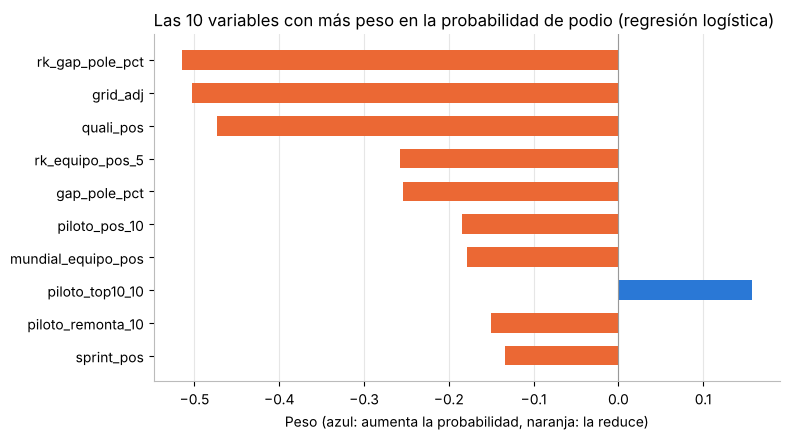

In [46]:
modelo_podio = logistica(C_ELEGIDO).fit(X(train), train.podio)
nombres = modelo_podio[:-1].get_feature_names_out(FEATURES)
pesos = pd.Series(modelo_podio[-1].coef_[0], index=nombres)
pesos = pesos[[n in FEATURES for n in pesos.index]]  # sin las columnas "había un vacío"
top = pesos.reindex(pesos.abs().sort_values(ascending=False).index).head(10)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index[::-1], top.values[::-1], color=[AZUL if v > 0 else NARANJA for v in top.values[::-1]], height=0.6)
ax.axvline(0, color="#999999", lw=0.8)
estilo(ax, "Las 10 variables con más peso en la probabilidad de podio (regresión logística)",
       "Peso (azul: aumenta la probabilidad, naranja: la reduce)")
ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Qué nos dice el gráfico.**

- Las tres variables con más peso miden lo mismo desde ángulos distintos: lo rápido que fue el piloto en clasificación (`rk_gap_pole_pct`, `grid_adj`, `quali_pos`). Todas tienen peso negativo porque un valor alto significa ir más atrás.
- Después vienen la forma del equipo (`rk_equipo_pos_5`, `mundial_equipo_pos`) y la del piloto (`piloto_pos_10`, `piloto_top10_10`). Es lo que vimos en el EDA: el coche pesa mucho.
- `sprint_pos` aparece entre las diez primeras: cuando hay sprint, su resultado aporta información sobre el ritmo de carrera.
- `piloto_remonta_10` tiene peso negativo, lo que puede sorprender. Una explicación posible: los pilotos que ganan muchos puestos en carrera suelen ser los que salen atrás con frecuencia; quien sale siempre delante no tiene puestos que ganar.

### 7.8 ¿Son creíbles las probabilidades?

Una buena log loss exige probabilidades **calibradas**: cuando el modelo dice "30 %", el piloto debería acabar en el podio aproximadamente 3 de cada 10 veces.

**Qué hace esta celda.** Con las predicciones finales de 2023, agrupa a los pilotos según la probabilidad de podio que les dimos (de 0 a 10 %, de 10 a 30 %, etc.) y compara, en cada grupo, la probabilidad media que predijimos con el porcentaje que realmente terminó en el podio.

In [47]:
pp_final, pt_final = predecir_p1(train, valid)
calib = pd.DataFrame({"predicho": pp_final, "real": valid.podio.values})
calib["grupo"] = pd.cut(calib.predicho, [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0])
(calib.groupby("grupo", observed=True)
 .agg(pilotos=("real", "size"), **{"% predicho": ("predicho", "mean"), "% real": ("real", "mean")})
 .assign(**{"% predicho": lambda t: (100 * t["% predicho"]).round(1), "% real": lambda t: (100 * t["% real"]).round(1)}))

,pilotos,% predicho,% real
grupo,,,
"(0.0, 0.1]",291,1.7,1.0
"(0.1, 0.3]",60,18.4,16.7
"(0.3, 0.5]",41,37.7,41.5
"(0.5, 0.7]",26,57.8,57.7
"(0.7, 0.9]",10,78.0,90.0
"(0.9, 1.0]",12,97.0,100.0


**Cómo leer la tabla.** En cada fila, las dos últimas columnas deberían parecerse. Con 440 pilotos y solo 66 podios en 2023, los grupos pequeños varían bastante por azar, así que no hay que esperar una coincidencia exacta. Lo importante es que el porcentaje real crezca con el predicho y que no haya grupos muy desviados.

### 7.9 Un ejemplo de principio a fin: GP de Singapur 2023

Las tablas de notas resumen cientos de pilotos en un solo número. Para ver qué hace realmente el modelo, seguimos una sola carrera.

**Por qué Singapur 2023.** Es una carrera en la que la parrilla engaña. Verstappen, que ganó 19 de las 22 carreras de 2023, salió 11.º, y Sainz, de Ferrari, salió desde la pole.

**Qué hace esta celda.** Para cada piloto de esa carrera muestra:

| Columna | Qué es |
|---|---|
| `parrilla` | probabilidad de podio según la referencia, que solo mira la posición de salida |
| `logistica`, `lightgbm` | probabilidad de podio según cada modelo con las 36 variables |
| `media` | la media de los dos |
| `final` | la media después del ajuste para que la carrera sume 3 |
| `resultado` | posición en la que terminó de verdad |

Las probabilidades se muestran en %.

In [48]:
p_parrilla_val = modelo_parrilla(train, valid).p_podio.values
ejemplo = valid.assign(parrilla=p_parrilla_val, logistica=p_lr["podio"], lightgbm=p_gb["podio"],
                       media=p_mix["podio"], final=pp_final)
singapur = ejemplo[ejemplo.name == "Singapore Grand Prix"].sort_values("grid_adj")
tabla_sing = singapur[["driverRef", "equipo", "grid_adj", "parrilla", "logistica", "lightgbm", "media", "final",
                       "positionOrder"]].rename(columns={"driverRef": "piloto", "grid_adj": "sale",
                                                         "positionOrder": "resultado"})
for c in ["parrilla", "logistica", "lightgbm", "media", "final"]:
    tabla_sing[c] = (100 * tabla_sing[c]).round(1)
print("Suma de probabilidades de podio en la carrera:")
print(f"  parrilla: {singapur.parrilla.sum():.2f}   media: {singapur.media.sum():.2f}   final: {singapur.final.sum():.2f}")
tabla_sing.head(13)

Suma de probabilidades de podio en la carrera:
  parrilla: 3.01   media: 2.76   final: 3.00


,piloto,equipo,sale,parrilla,logistica,lightgbm,media,final,resultado
26127,sainz,ferrari,1,87.1,47.4,56.6,52.0,56.5,1
26133,russell,mercedes,2,65.8,40.0,57.9,48.9,53.1,16
26131,leclerc,ferrari,3,46.0,33.2,51.8,42.5,46.2,4
26132,norris,mclaren,4,31.2,25.2,38.9,32.1,34.9,2
26120,hamilton,mercedes,5,21.1,30.3,34.9,32.6,35.4,3
26125,kevin_magnussen,haas,6,14.4,1.2,1.9,1.6,1.7,10
26121,alonso,aston_martin,7,9.9,11.5,11.2,11.4,12.4,15
26128,ocon,alpine,8,6.9,2.5,2.5,2.5,2.7,18
26122,hulkenberg,haas,9,4.9,0.8,1.3,1.1,1.2,13
26139,lawson,rb,10,3.5,0.3,0.8,0.5,0.6,9


**Cómo leer la tabla, fila a fila.**

- **Sainz** (sale 1.º). La parrilla le da un 87 %, porque el que sale en la pole suele acabar en el podio. Los modelos lo bajan a un 57 %: saben que su Ferrari no venía siendo de los más rápidos en carrera (su equipo terminaba de media en torno al 9.º puesto en las cinco carreras anteriores). Ganó la carrera, así que aquí la parrilla acertaba con más seguridad.
- **Verstappen** (sale 11.º). La parrilla le da un 2,6 %: casi nadie sube del 11.º al podio. Los modelos lo suben a un 40 %, porque saben que su Red Bull es con diferencia el coche más rápido (posición media de su equipo en las cinco carreras anteriores: 2,2) y que lidera el mundial. Terminó 5.º: remontó mucho, pero no llegó al podio.
- **Hamilton** (sale 5.º). Del 21 % de la parrilla al 35 %, por la forma de Mercedes. Terminó 3.º.
- **Russell** (sale 2.º). Del 66 % al 53 %. Chocó en la última vuelta y terminó 16.º. Ningún modelo puede prever un accidente concreto.
- **Magnussen, Ocon, Hülkenberg** (salen 6.º, 8.º y 9.º). La parrilla les da opciones pequeñas pero reales; los modelos las bajan casi a cero porque sus equipos venían terminando lejos de los puestos de cabeza.

**El ajuste a 3.** La suma de la columna `media` es 2,76: los modelos "esperaban" ver menos de tres pilotos en el podio. El ajuste multiplica todas las probabilidades por el mismo número para que sumen 3, y por eso `final` es algo mayor que `media` en todos los pilotos con opciones.

**¿Quién acierta más en esta carrera?** Recordemos cómo castiga la log loss (sección 6.2): a cada piloto se le pone una penalización según la probabilidad que dimos a lo que pasó. Si acabó en el podio, cuenta la probabilidad de podio; si no, la de "no podio".

**Qué hace esta celda.** Calcula la penalización de cada piloto con la referencia y con el modelo final, y después la media de cada carrera de 2023 para comparar.

In [49]:
def penalizacion(p, y):
    return -np.log(np.where(y == 1, p, 1 - p))


ejemplo["penaliz_parrilla"] = penalizacion(ejemplo.parrilla, ejemplo.podio)
ejemplo["penaliz_modelo"] = penalizacion(ejemplo.final, ejemplo.podio)
print(ejemplo.loc[ejemplo.name == "Singapore Grand Prix",
                  ["driverRef", "grid_adj", "podio", "penaliz_parrilla", "penaliz_modelo"]]
      .sort_values("grid_adj").head(11).round(3).to_string(index=False))

por_carrera = ejemplo.groupby("name")[["penaliz_parrilla", "penaliz_modelo"]].mean()
sing = por_carrera.loc["Singapore Grand Prix"]
print(f"\nMedia en Singapur: parrilla {sing.penaliz_parrilla:.3f}, modelo {sing.penaliz_modelo:.3f}")
gana = (por_carrera.penaliz_modelo < por_carrera.penaliz_parrilla).sum()
print(f"El modelo tiene menos penalización que la parrilla en {gana} de las {len(por_carrera)} carreras de 2023.")

      driverRef  grid_adj  podio  penaliz_parrilla  penaliz_modelo
          sainz         1      1             0.138           0.572
        russell         2      0             1.072           0.758
        leclerc         3      0             0.616           0.619
         norris         4      1             1.164           1.054
       hamilton         5      1             1.555           1.038
kevin_magnussen         6      0             0.155           0.017
         alonso         7      0             0.105           0.132
           ocon         8      0             0.072           0.027
     hulkenberg         9      0             0.051           0.012
         lawson        10      0             0.036           0.006
 max_verstappen        11      0             0.026           0.515

Media en Singapur: parrilla 0.253, modelo 0.245
El modelo tiene menos penalización que la parrilla en 16 de las 22 carreras de 2023.


**Qué nos dice.**

- En Singapur el modelo gana con Russell, Norris, Hamilton y los pilotos de la zona media, y pierde con Sainz y Verstappen. Con Verstappen, la parrilla acertó al darle pocas opciones (penalización 0,03) y el modelo, al darle un 40 %, se lleva 0,52. En el conjunto de la carrera quedan casi empatados.
- Mirando toda la temporada, el modelo tiene menos penalización que la parrilla en 16 de las 22 carreras.

Es la idea más importante de esta sección: **un modelo de probabilidades no acierta siempre**. Fallará en carreras concretas, por un accidente o una remontada que no llega. Lo que buscamos es que, sumando muchas carreras, sus probabilidades se acerquen más a la realidad que las de la parrilla.

### 7.10 Resumen de la Parte 1

| Modelo (validación 2023) | Log loss media |
|---|---|
| Sin información | 0,558 |
| Solo parrilla (referencia) | 0,391 |
| **Media logística + LightGBM, ajustada a 3/10 (elegido)** | **≈ 0,339** |

El modelo elegido queda en la función `predecir_p1`. En la sección 10 la entrenaremos con 2014-2023 y la aplicaremos a 2024.

In [50]:
pd.DataFrame(notas_p1).round(4)

,log loss podio,log loss top10,PARTE 1 (log loss media)
Solo parrilla,0.2514,0.5302,0.3908
Logística (36 variables),0.2225,0.4631,0.3428
LightGBM (36 variables),0.2263,0.4634,0.3448
Media logística + LightGBM,0.2206,0.4612,0.3409
Logística + ajuste 3/10,0.2167,0.4633,0.3400
LightGBM + ajuste 3/10,0.2239,0.4638,0.3439
Media logística + LightGBM + ajuste 3/10,0.2164,0.4610,0.3387


## 8. Parte 2: predecir la posición

**El objetivo.** Dar a cada piloto un número, `posicion_pred`. El reto lo convierte en un orden dentro de cada carrera (el valor más bajo, primero) y lo compara con el orden real mediante el Spearman medio. La referencia, que predice "cada uno termina donde sale", consigue **0,597** en 2023. Más alto es mejor.

**Lo que importa es el orden, no el número.** Si a tres pilotos les damos 1,2, 1,9 y 7,5, el reto los ordena 1.º, 2.º y 3.º. Da igual que el número no sea una posición "redonda": solo cuenta quién va delante de quién.

**El reto pide probar al menos dos formas.** Probamos tres:

| Forma | Idea | Sección |
|---|---|---|
| **Regresión** | predecir directamente el número de la posición final (1, 2, 3…) | 8.2 |
| **Ranking** | un modelo que aprende a ordenar a los pilotos de una carrera | 8.3 |
| **Desde las probabilidades** | ordenar por las `p_podio` y `p_top10` de la Parte 1 | 8.4 |

Después las combinamos (8.5) y comprobamos que la elección se mantiene en 2021 y 2022 (8.6).

### 8.1 Herramientas

**Qué hace esta celda.**

- `nota_p2` mide una predicción con las métricas de la Parte 2: Spearman medio y MAE.
- `sin_empates` evita el problema que vimos en la sección 6.3: si dos pilotos tienen exactamente el mismo valor, el orden lo decidiría la posición de las filas en el fichero. Para que eso no ocurra, sumamos al valor una cantidad minúscula proporcional a la parrilla (una millonésima por puesto). No cambia ningún orden salvo los empates, que se resuelven a favor del que sale más adelante.
- `orden_en_carrera` convierte cualquier puntuación en un orden 1, 2, 3… dentro de cada carrera. Lo usaremos para combinar modelos.

In [51]:
from sklearn.linear_model import Ridge


def sin_empates(valor, d):
    return np.asarray(valor, dtype=float) + d.grid_adj.values * 1e-6


def nota_p2(posicion_pred, real, nombre):
    pred = pd.DataFrame({"raceId": real.raceId, "p_podio": 0.1, "p_top10": 0.5,
                         "posicion_pred": sin_empates(posicion_pred, real)}, index=real.index)
    return evaluar(pred, real, nombre)[["PARTE 2 (Spearman medio)", "MAE"]]


def orden_en_carrera(valor, d):
    return pd.Series(np.asarray(valor, dtype=float), index=d.index).groupby(d.raceId).rank().values


notas_p2 = [nota_p2(valid.grid_adj, valid, "Solo parrilla")]
pd.DataFrame(notas_p2).round(4)

,PARTE 2 (Spearman medio),MAE
Solo parrilla,0.5973,3.7091


### 8.2 Opción 1: regresión sobre la posición

**La idea.** Es la más directa: el modelo aprende a predecir el número de la posición final. Para un piloto que viene ganando y sale delante predecirá algo como 2,3; para uno de un equipo lento, algo como 15,8.

**Dos modelos.**

- **Ridge**: una regresión lineal, la versión "de números" de la regresión logística. Da a cada variable un peso y los suma. Como con la logística, rellenamos los vacíos y ponemos las variables en la misma escala. Su hiperparámetro `alpha` funciona como el `C` de la logística pero al revés: un `alpha` mayor es un modelo más prudente.
- **LightGBM en versión regresión**: los mismos árboles pequeños de la Parte 1, pero prediciendo un número en lugar de una probabilidad.

**Qué hace esta celda.** Prueba Ridge con tres valores de `alpha` y LightGBM, entrena con 2014-2022 y mide en 2023.

In [52]:
def ridge(alpha):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), Ridge(alpha=alpha))


def lgb_regresion():
    return lgb.LGBMRegressor(num_leaves=4, n_estimators=600, learning_rate=0.01, min_child_samples=100,
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.7, random_state=SEED, verbose=-1)


filas = []
for alpha in [1, 10, 100]:
    filas.append(nota_p2(ridge(alpha).fit(X(train), train.positionOrder).predict(X(valid)), valid, f"Ridge alpha = {alpha}"))
filas.append(nota_p2(lgb_regresion().fit(X(train), train.positionOrder).predict(X(valid)), valid, "LightGBM regresión"))
pd.DataFrame(filas).round(4)

,PARTE 2 (Spearman medio),MAE
Ridge alpha = 1,0.6630,3.2591
Ridge alpha = 10,0.6656,3.2455
Ridge alpha = 100,0.6659,3.2500
LightGBM regresión,0.6651,3.3045


**Qué mirar en la salida.** Todas pasan de 0,597 a alrededor de 0,665. Los valores de `alpha` dan resultados casi iguales; nos quedamos con `alpha = 10`. LightGBM queda prácticamente empatado con Ridge.

In [53]:
ALPHA_ELEGIDO = 10
pos_ridge = ridge(ALPHA_ELEGIDO).fit(X(train), train.positionOrder).predict(X(valid))
notas_p2.append(nota_p2(pos_ridge, valid, "Regresión (Ridge)"))
pd.DataFrame(notas_p2).round(4)

,PARTE 2 (Spearman medio),MAE
Solo parrilla,0.5973,3.7091
Regresión (Ridge),0.6656,3.2455


### 8.3 Opción 2: modelo de ranking (LGBMRanker)

**La idea.** La regresión intenta acertar el número exacto de cada piloto por separado. Pero el reto solo mira el orden dentro de cada carrera. Un **modelo de ranking** está pensado justo para eso: aprende carrera a carrera a poner a unos pilotos delante de otros, igual que un buscador aprende a ordenar resultados.

**Cómo se le explica qué orden es mejor.** El modelo necesita una puntuación de "relevancia" para cada piloto, donde más alto significa mejor. Usamos `relevancia = número de coches − posición final`. En una carrera de 20 coches, el ganador tiene 19 y el último, 0.

**Qué es `lambdarank`.** Es el método de aprendizaje que usa el ranker (el que propone el reto). Se fija sobre todo en acertar las primeras posiciones del orden. El ranker también necesita saber qué filas forman cada carrera: se lo indicamos con `group`, la lista de cuántos pilotos hay en cada carrera, en el mismo orden que las filas.

**Qué hace esta celda.** Entrena el ranker con 2014-2022 y mide en 2023. El ranker devuelve una puntuación en la que más alto es mejor; como en `posicion_pred` más bajo es mejor, le cambiamos el signo.

In [54]:
def entrenar_ranker(entrena):
    entrena = entrena.sort_values(["race_idx", "grid_adj"])
    relevancia = (entrena.n_coches - entrena.positionOrder).clip(lower=0).astype(int)
    tam_carreras = entrena.groupby("race_idx", sort=False).size().values
    modelo = lgb.LGBMRanker(objective="lambdarank", label_gain=list(range(40)),
                            num_leaves=4, n_estimators=600, learning_rate=0.02, min_child_samples=100,
                            subsample=0.8, subsample_freq=1, colsample_bytree=0.7, random_state=SEED, verbose=-1)
    return modelo.fit(X(entrena), relevancia, group=tam_carreras)


pos_ranker = -entrenar_ranker(train).predict(X(valid))
notas_p2.append(nota_p2(pos_ranker, valid, "Ranking (LGBMRanker)"))
pd.DataFrame(notas_p2).round(4)

,PARTE 2 (Spearman medio),MAE
Solo parrilla,0.5973,3.7091
Regresión (Ridge),0.6656,3.2455
Ranking (LGBMRanker),0.6651,3.2864


### 8.4 Opción 3: el orden a partir de las probabilidades de la Parte 1

**La idea.** Ya tenemos, para cada piloto, la probabilidad de podio y la de top 10. Un piloto con más probabilidad de las dos cosas debería terminar más adelante. Ordenamos por la suma `p_podio + p_top10`: la de top 10 separa bien a la zona media, y la de podio, a los de cabeza.

**Qué hace esta celda.** Usa las probabilidades finales de la Parte 1 para 2023 (`pp_final`, `pt_final`, calculadas en la sección 7.8) y ordena por su suma, con el signo cambiado porque más probabilidad significa mejor posición.

In [55]:
pos_prob = -(pp_final + pt_final)
notas_p2.append(nota_p2(pos_prob, valid, "Desde probabilidades"))
pd.DataFrame(notas_p2).round(4)

,PARTE 2 (Spearman medio),MAE
Solo parrilla,0.5973,3.7091
Regresión (Ridge),0.6656,3.2455
Ranking (LGBMRanker),0.6651,3.2864
Desde probabilidades,0.6620,3.3227


**Qué mirar en la salida.** Las tres opciones quedan muy juntas, entre 0,662 y 0,666, y todas superan con claridad a la parrilla. El MAE también baja: de 3,7 puestos de error medio con la parrilla a unos 3,25.

### 8.5 Combinar regresión y ranking

Como en la Parte 1, combinar modelos que se equivocan de forma distinta suele ayudar. Pero aquí hay un detalle: la regresión da números del estilo "4,3" y el ranker, puntuaciones de otra escala (por ejemplo, "−1,7"). No se pueden promediar directamente.

**La solución.** Convertimos cada predicción en un orden dentro de la carrera (1.º, 2.º, 3.º…) con `orden_en_carrera` y sumamos los dos órdenes. Si la regresión pone a un piloto 3.º y el ranker 5.º, su valor combinado es 8; el que tenga el valor más bajo de la carrera irá primero.

**Qué hace esta celda.** Mide dos combinaciones: regresión + ranking, y las tres opciones juntas.

In [56]:
comb_2 = orden_en_carrera(pos_ridge, valid) + orden_en_carrera(pos_ranker, valid)
comb_3 = comb_2 + orden_en_carrera(pos_prob, valid)
notas_p2.append(nota_p2(comb_2, valid, "Regresión + ranking"))
notas_p2.append(nota_p2(comb_3, valid, "Regresión + ranking + probabilidades"))
pd.DataFrame(notas_p2).round(4)

,PARTE 2 (Spearman medio),MAE
Solo parrilla,0.5973,3.7091
Regresión (Ridge),0.6656,3.2455
Ranking (LGBMRanker),0.6651,3.2864
Desde probabilidades,0.6620,3.3227
Regresión + ranking,0.6683,3.2500
Regresión + ranking + probabilidades,0.6637,3.2909


### 8.6 ¿Se mantiene en otros años?

Las diferencias entre opciones son de milésimas, así que 2023 por sí solo no basta para elegir. Repetimos todo validando en 2021 y en 2022, como hicimos en la Parte 1.

**Qué hace esta celda.** Para cada año, entrena con los anteriores, calcula las cinco opciones y mide el Spearman. Al final muestra la media de los tres años.

In [57]:
def predecir_p2(entrena, predice, p_podio=None, p_top10=None):
    """Devuelve las cinco opciones de la Parte 2. La elegida es 'Regresión + ranking'."""
    reg = ridge(ALPHA_ELEGIDO).fit(X(entrena), entrena.positionOrder).predict(X(predice))
    rnk = -entrenar_ranker(entrena).predict(X(predice))
    if p_podio is None:
        p_podio, p_top10 = predecir_p1(entrena, predice)
    prob = -(p_podio + p_top10)
    comb = orden_en_carrera(reg, predice) + orden_en_carrera(rnk, predice)
    return {"Regresión (Ridge)": reg, "Ranking (LGBMRanker)": rnk, "Desde probabilidades": prob,
            "Regresión + ranking": comb,
            "Regresión + ranking + probabilidades": comb + orden_en_carrera(prob, predice)}


filas = []
for anio in [2021, 2022, 2023]:
    tr, va = datos[datos.year < anio], datos[datos.year == anio]
    fila = {"año validado": anio, "Solo parrilla": nota_p2(va.grid_adj, va, "")["PARTE 2 (Spearman medio)"]}
    for nombre, valor in predecir_p2(tr, va).items():
        fila[nombre] = nota_p2(valor, va, "")["PARTE 2 (Spearman medio)"]
    filas.append(fila)
robustez_p2 = pd.DataFrame(filas).set_index("año validado")
robustez_p2.loc["media"] = robustez_p2.mean()
robustez_p2.round(4).T

año validado,2021,2022,2023,media
Solo parrilla,0.6487,0.5262,0.5973,0.5907
Regresión (Ridge),0.6934,0.6031,0.6656,0.6540
Ranking (LGBMRanker),0.6893,0.6128,0.6651,0.6557
Desde probabilidades,0.6909,0.6070,0.6620,0.6533
Regresión + ranking,0.6958,0.6049,0.6683,0.6563
Regresión + ranking + probabilidades,0.6921,0.6040,0.6637,0.6532


**Qué mirar en la salida.**

- Las cinco opciones superan a la parrilla todos los años, en 0,05 a 0,09 puntos.
- Ninguna gana siempre: las diferencias entre ellas son de unas milésimas y cambian de un año a otro.
- **Regresión + ranking** tiene la mejor media de los tres años y es la mejor en 2021 y 2023. La elegimos.

Combinar las tres opciones no mejora: la tercera (desde probabilidades) usa casi la misma información que las otras dos, así que no aporta un punto de vista nuevo.

### 8.7 Un ejemplo: Singapur 2023 otra vez

**Qué hace esta celda.** Muestra, para los pilotos de Singapur 2023, desde dónde salían, en qué posición los coloca el modelo elegido y dónde terminaron.

In [58]:
valid_sing = valid.assign(pos_modelo=pd.Series(comb_2, index=valid.index)
                          .pipe(lambda s: (s + valid.grid_adj * 1e-6).groupby(valid.raceId).rank(method="first")))
(valid_sing[valid_sing.name == "Singapore Grand Prix"]
 .sort_values("grid_adj")[["driverRef", "equipo", "grid_adj", "pos_modelo", "positionOrder"]]
 .rename(columns={"driverRef": "piloto", "grid_adj": "sale", "pos_modelo": "predicción", "positionOrder": "terminó"})
 .astype({"predicción": int}).head(14))

,piloto,equipo,sale,predicción,terminó
26127,sainz,ferrari,1,1,1
26133,russell,mercedes,2,3,16
26131,leclerc,ferrari,3,4,4
26132,norris,mclaren,4,5,2
26120,hamilton,mercedes,5,6,3
26125,kevin_magnussen,haas,6,9,10
26121,alonso,aston_martin,7,7,15
26128,ocon,alpine,8,10,18
26122,hulkenberg,haas,9,11,13
26139,lawson,rb,10,14,9


**Cómo leerlo.**

- **Verstappen** sale 11.º y el modelo lo coloca 2.º, porque su Red Bull era el coche más rápido. Terminó 5.º: remontó, aunque menos de lo previsto.
- **Pérez**, su compañero, sale 13.º; el modelo lo pone 8.º y terminó exactamente 8.º.
- **Magnussen, Ocon y Hülkenberg** salen 6.º, 8.º y 9.º, y el modelo los retrasa unos puestos porque sus equipos venían terminando en la zona media-baja. Acabaron todavía más atrás.
- **Russell** sale 2.º y el modelo lo deja 3.º. Su accidente en la última vuelta (terminó 16.º) no lo puede prever nadie.

El modelo no acierta cada posición, pero corrige la parrilla en la dirección correcta en la mayoría de los casos, y eso es lo que sube el Spearman.

### 8.8 Resumen de la Parte 2

| Modelo (validación) | Spearman 2023 | Spearman medio 2021-2023 |
|---|---|---|
| Solo parrilla (referencia) | 0,597 | 0,591 |
| **Regresión + ranking (elegido)** | **≈ 0,668** | **≈ 0,656** |

La función `predecir_p2` contiene el modelo. En la sección 10 la entrenaremos con 2014-2023 y la aplicaremos a 2024.

## 9. Análisis de errores: dónde falla el modelo

**Para qué sirve.** Una nota media (0,668 de Spearman, 0,339 de log loss) no dice **dónde** se equivoca el modelo. Mirar los errores uno a uno sirve para dos cosas: saber qué parte del error se puede mejorar y cuál no se puede prever con los datos del sábado, y explicar al jefe de estrategia en qué casos fiarse menos de la predicción.

El reto propone tres sospechosos: **los abandonos**, **la lluvia** (que no está en los datos) y **los equipos que cambian de nivel entre temporadas**. Los revisamos con la validación de 2023. Seguimos sin mirar 2024.

**Una aclaración sobre la regla de las variables prohibidas.** En esta sección sí usamos datos de la propia carrera (si el piloto abandonó, sus tiempos por vuelta). Está permitido porque **no son variables del modelo**: son la "respuesta" con la que examinamos sus errores, después de predecir. Nada de lo que se calcula aquí vuelve al modelo.

### 9.1 Preparar la tabla de errores

**Qué hace esta celda.** Para cada piloto de 2023 guarda el orden que predice el modelo elegido de la Parte 2 (`pred`) y calcula su error: `error = pred − posición real`.

- **Error negativo**: el modelo lo colocó **más adelante** de donde terminó. Lo sobrestimó.
- **Error positivo**: lo colocó **más atrás**. Lo subestimó.
- **Error absoluto**: los puestos de diferencia, sin signo.

In [59]:
errores = valid.copy()
errores["pred"] = (pd.Series(sin_empates(comb_2, valid), index=valid.index)
                   .groupby(valid.raceId).rank(method="first"))
errores["error"] = errores.pred - errores.positionOrder
errores["error_abs"] = errores.error.abs()
errores["p_podio"], errores["p_top10"] = pp_final, pt_final
print(f"Error medio absoluto en 2023: {errores.error_abs.mean():.2f} puestos")

Error medio absoluto en 2023: 3.25 puestos


### 9.2 Los abandonos

**La sospecha.** Un piloto que abandona termina al final del orden, venga de donde venga. Si el modelo lo puso 3.º y abandona, se equivoca en muchos puestos de golpe. Y como vimos en la sección 4.1, Spearman castiga mucho los errores grandes.

**Qué hace esta celda.**

1. Compara el error medio de los pilotos que terminaron con el de los que no.
2. Para cada carrera calcula el Spearman con todos los pilotos y el Spearman **solo con los que terminaron**. La diferencia entre los dos es, aproximadamente, lo que nos cuestan los abandonos.
3. Mide si las carreras con más abandonos son las que peor predecimos.

Error medio absoluto (puestos):
               error medio  pilotos
terminado                          
no terminaron         6.67       66
terminaron            2.65      374

Spearman medio con todos:          0.668
Spearman medio solo con terminados: 0.798
Correlación entre nº de abandonos y Spearman de la carrera: -0.69


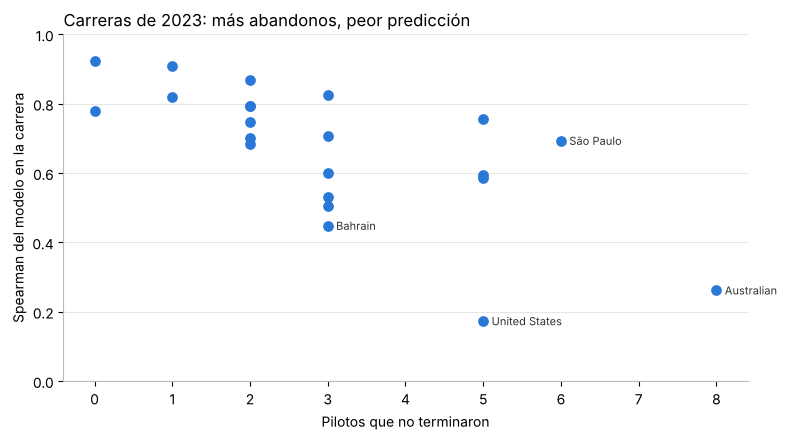

In [60]:
print("Error medio absoluto (puestos):")
print(errores.groupby(errores.terminado.map({True: "terminaron", False: "no terminaron"}))
      .error_abs.agg(["mean", "size"]).rename(columns={"mean": "error medio", "size": "pilotos"}).round(2))


def sp_pred(g):
    return spearmanr(g.pred, g.positionOrder).correlation


por_carrera_err = errores.groupby("name").apply(lambda g: pd.Series({
    "ronda": g["round"].iloc[0],
    "abandonos": (~g.terminado).sum(),
    "spearman": sp_pred(g),
    "spearman solo terminados": sp_pred(g[g.terminado]),
})).sort_values("ronda")

print(f"\nSpearman medio con todos:          {por_carrera_err.spearman.mean():.3f}")
print(f"Spearman medio solo con terminados: {por_carrera_err['spearman solo terminados'].mean():.3f}")
print(f"Correlación entre nº de abandonos y Spearman de la carrera: "
      f"{por_carrera_err.abandonos.corr(por_carrera_err.spearman):.2f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(por_carrera_err.abandonos, por_carrera_err.spearman, color=AZUL, s=45, zorder=3)
for nombre, fila in por_carrera_err.iterrows():
    if fila.spearman < 0.5 or fila.abandonos >= 6:
        ax.annotate(nombre.replace(" Grand Prix", ""), (fila.abandonos, fila.spearman),
                    xytext=(6, 0), textcoords="offset points", fontsize=8, color="#333333", va="center")
ax.set_ylim(0, 1)
estilo(ax, "Carreras de 2023: más abandonos, peor predicción", "Pilotos que no terminaron",
       "Spearman del modelo en la carrera")
plt.tight_layout()
plt.show()

**Qué nos dice.**

- Con los pilotos que terminan, el modelo se equivoca de media en unos 2,6 puestos. Con los que abandonan, en unos 6,7. Uno de cada siete pilotos no termina, pero esos pilotos acumulan una parte enorme del error.
- Si quitamos a los que abandonan, el Spearman medio sube de 0,67 a 0,80. Es decir, **los abandonos son la mayor fuente de error**.
- La relación se ve en el gráfico: las carreras con más abandonos tienen un Spearman más bajo (correlación de −0,69). Las peores son Estados Unidos y Australia. En Austin, además, dos pilotos fueron descalificados después de la carrera; en Melbourne hubo 8 pilotos sin terminar.

**¿Se puede mejorar?** Solo en parte. El modelo ya tiene variables de fiabilidad (`equipo_averias_10`, `piloto_abandonos_10`), pero que un coche concreto rompa el motor o choque en una carrera concreta es, en gran medida, azar. Las probabilidades de la Parte 1 lo recogen mejor que la posición, porque nunca dan un 100 % a nadie.

### 9.3 La lluvia

**El problema.** El dataset no dice si llovió. La lluvia cambia mucho una carrera: los pilotos con más habilidad en mojado ganan puestos, hay más salidas de pista y las estrategias de neumáticos lo trastocan todo.

**¿Podemos detectarla con los datos que hay?** Una idea razonable: con la pista mojada se rueda mucho más despacio. Si comparamos el tiempo mediano por vuelta en carrera con el tiempo de la pole, una carrera en mojado debería salir con un cociente mucho más alto de lo normal.

**Qué hace esta celda.** Calcula ese cociente para cada carrera de 2023 con `lap_times.csv` y lo muestra junto al Spearman del modelo.

In [61]:
mediana_vuelta = tablas["lap_times"].groupby("raceId").milliseconds.median() / 1000
pole = tablas["qualifying"].groupby("raceId").mejor_quali_s.min()
lluvia = (por_carrera_err
          .join(errores.groupby("name").raceId.first())
          .join((mediana_vuelta / pole).rename("vuelta carrera / pole"), on="raceId")
          [["spearman", "spearman solo terminados", "vuelta carrera / pole"]]
          .sort_values("vuelta carrera / pole", ascending=False))
print("Correlación entre el cociente y el Spearman:",
      round(lluvia["vuelta carrera / pole"].corr(lluvia.spearman), 2))
lluvia.round(3)

Correlación entre el cociente y el Spearman: 0.03


,spearman,spearman solo terminados,vuelta carrera / pole
name,,,
Japanese Grand Prix,0.756,0.971,1.115
Monaco Grand Prix,0.794,0.841,1.112
Spanish Grand Prix,0.779,0.779,1.112
Hungarian Grand Prix,0.824,0.841,1.106
Singapore Grand Prix,0.586,0.689,1.105
Dutch Grand Prix,0.532,0.591,1.103
Bahrain Grand Prix,0.448,0.703,1.099
Austrian Grand Prix,0.820,0.858,1.097
São Paulo Grand Prix,0.693,0.771,1.090


**Qué nos dice.** El indicador no funciona como detector de lluvia. Los cocientes van de 1,06 a 1,12 sin ningún caso claramente separado, y no tienen relación con el Spearman. Hay varios motivos: en carrera los coches salen con mucha gasolina y gestionan neumáticos, y los coches de seguridad ralentizan muchas vueltas. Todo eso pesa tanto como la lluvia.

Hay un caso curioso que confirma el problema por el otro lado: Canadá sale con un cociente **menor que 1**, es decir, la vuelta mediana de carrera fue más rápida que la pole. Eso pasa cuando lo que se moja es la **clasificación**: el sábado se rodó despacio y el domingo, en seco, más deprisa. El indicador mezcla la lluvia del sábado con la del domingo.

**Conclusión.** Con estos datos no podemos identificar las carreras con lluvia, ni para analizarlas ni, menos aún, para predecirlas. Es un error que asumimos. Un equipo real usaría la previsión meteorológica del domingo, que se conoce el sábado por la noche; aquí no la tenemos.

### 9.4 Equipos que cambian de nivel

**La sospecha.** Las variables de forma miran hacia atrás. Si un equipo mejora mucho de un año a otro, al principio de la temporada sus medias móviles todavía reflejan el año anterior, y el modelo debería subestimarlo. Si empeora, debería sobrestimarlo.

**Qué hace esta celda.** Para cada equipo calcula:

- `cambio`: cuánto mejoró (negativo) o empeoró (positivo) su posición media de 2022 a 2023.
- `error rondas 1-6` y `error resto`: el error medio del modelo con ese equipo al principio de la temporada y después. Negativo = el modelo lo sobrestimó.
- `error parrilla 1-6`: el mismo cálculo para la referencia de la parrilla, para comparar.

In [62]:
nivel = datos[datos.year.isin([2022, 2023])].groupby(["equipo", "year"]).positionOrder.mean().unstack()
nivel["cambio"] = nivel[2023] - nivel[2022]
inicio = errores["round"] <= 6
errores["orden_parrilla"] = errores.groupby("raceId").grid_adj.rank(method="first")
equipos = nivel.rename(columns={2022: "pos. media 2022", 2023: "pos. media 2023"}).join([
    errores[inicio].groupby("equipo").error.mean().rename("error rondas 1-6"),
    errores[~inicio].groupby("equipo").error.mean().rename("error resto"),
    (errores.orden_parrilla - errores.positionOrder)[inicio].groupby(errores.equipo).mean().rename("error parrilla 1-6"),
]).sort_values("cambio")
equipos.round(2)

,pos. media 2022,pos. media 2023,cambio,error rondas 1-6,error resto,error parrilla 1-6
equipo,,,,,,
aston_martin,11.89,8.91,-2.98,-0.58,0.31,-0.50
mclaren,10.64,9.45,-1.18,-0.08,-1.06,0.00
red_bull,4.45,3.57,-0.89,0.00,-0.09,3.33
williams,14.95,14.11,-0.84,1.42,1.97,-0.50
rb,13.52,13.61,0.09,2.00,1.88,1.00
haas,14.27,15.07,0.80,1.33,0.81,-0.42
sauber,13.20,14.00,0.80,1.17,1.62,0.67
ferrari,6.68,7.86,1.18,-4.33,-2.88,-3.50
alpine,9.86,11.27,1.41,0.08,-0.25,-0.25


**Qué nos dice.** La sospecha no se cumple como esperábamos:

- **Aston Martin** fue el equipo que más mejoró (de 11,9 a 8,9 de media), y aun así el modelo apenas se equivoca con él al principio de 2023 (−0,6 puestos). El motivo: las variables de **clasificación** del propio fin de semana detectan enseguida que el coche es rápido, aunque la forma de las carreras anteriores todavía no lo refleje.
- El error grande está en **Ferrari y Mercedes**, que el modelo sobrestima toda la temporada, sobre todo Ferrari (−4,3 puestos en las seis primeras carreras). La parrilla también los sobrestima. En 2023 Ferrari clasificaba mucho mejor de lo que luego rendía en carrera, y además tuvo abandonos al principio del año.
- En el otro extremo, el modelo subestima a los equipos de la zona baja (Williams, RB, Sauber, Haas) en 1-2 puestos. Es la otra cara de lo anterior: si un coche de cabeza termina más atrás de lo previsto, alguno de los de detrás termina más adelante.

**Conclusión.** El cambio de nivel entre temporadas no es el problema principal, porque la clasificación lo corrige pronto. Lo que se le escapa al modelo es la diferencia entre **ritmo a una vuelta** (sábado) y **ritmo de carrera** (domingo) de algunos coches.

**Una mejora posible.** `lap_times.csv` de carreras **anteriores** permitiría medir el ritmo de carrera de cada coche (por ejemplo, su vuelta mediana comparada con la del ganador). Sería una variable legítima y atacaría justo este error. La dejamos como trabajo futuro.

### 9.5 ¿Cambia el error a lo largo de la temporada?

**Qué hace esta celda.** Divide 2023 en cuatro tramos de rondas y calcula el Spearman medio del modelo y de la parrilla en cada uno.

In [63]:
errores["tramo"] = pd.cut(errores["round"], [0, 6, 12, 18, 30], labels=["rondas 1-6", "7-12", "13-18", "19-22"])
tramos = errores.groupby("tramo", observed=True).apply(lambda g: pd.Series({
    "modelo": g.groupby("raceId").apply(sp_pred).mean(),
    "parrilla": g.groupby("raceId").apply(lambda x: spearmanr(x.grid_adj, x.positionOrder).correlation).mean(),
}))
tramos["mejora"] = tramos.modelo - tramos.parrilla
tramos.round(3)

,modelo,parrilla,mejora
tramo,,,
rondas 1-6,0.674,0.632,0.042
7-12,0.753,0.626,0.127
13-18,0.557,0.531,0.026
19-22,0.700,0.607,0.093


**Qué nos dice.** El modelo supera a la parrilla en todos los tramos, también al principio del año, cuando las medias de forma vienen en parte de la temporada anterior. El tramo más difícil para los dos es el de las rondas 13-18 (Países Bajos, Singapur, Japón, Catar, Estados Unidos…), que incluye varias de las carreras con más abandonos.

### 9.6 Resumen del análisis de errores

| Fuente de error | ¿Cuánto pesa? | ¿Se puede corregir con los datos del sábado? |
|---|---|---|
| **Abandonos** | la mayor: sin ellos, el Spearman pasaría de 0,67 a 0,80 | poco: es en gran parte azar; ya usamos la fiabilidad reciente |
| **Lluvia** | no se puede medir con estos datos | no: haría falta la previsión meteorológica |
| **Cambio de nivel entre temporadas** | pequeño: la clasificación lo corrige pronto | ya está bastante corregido |
| **Ritmo de carrera distinto del de clasificación** (Ferrari y Mercedes en 2023) | moderado | en parte: con variables de ritmo de carrera a partir de `lap_times` de carreras anteriores |

Con esto termina el trabajo de validación. Falta la entrega: entrenar los modelos elegidos con 2014-2023 y predecir 2024.

## 10. Entrega: entrenar con 2014-2023, predecir 2024 y exportar

**Qué cambia respecto a la validación.** Hasta ahora entrenábamos con 2014-2022 y medíamos en 2023 para **elegir** los modelos. Las elecciones ya están hechas y no se tocan:

| Parte | Modelo elegido | Función |
|---|---|---|
| 1. Probabilidades | media de logística (`C` = 0,03) y LightGBM (4 hojas), ajustada a 3 y 10 por carrera | `predecir_p1` |
| 2. Posición | suma del orden de la regresión Ridge (`alpha` = 10) y del LGBMRanker | `predecir_p2` |

Ahora reentrenamos esos mismos modelos con **todos** los años permitidos, 2014-2023, porque así aprenden también de la temporada más reciente. Después predecimos 2024.

**¿Usamos algo de 2024?** Solo lo que permite el reto: las variables de 2024 (parrilla, clasificación, sprint y forma con las carreras **anteriores** de 2024) se calcularon en la sección 5 con las mismas funciones y las mismas comprobaciones de fuga. El resultado de 2024 no se usa para entrenar ni para elegir nada.

### 10.1 Entrenar y predecir

**Qué hace esta celda.**

1. Separa `train_final` (2014-2023) y `test` (2024).
2. Calcula las probabilidades con `predecir_p1` y la posición con `predecir_p2`, pasándole esas mismas probabilidades para no entrenar los modelos de la Parte 1 dos veces.
3. Convierte la posición combinada en un orden 1, 2, 3… dentro de cada carrera, deshaciendo empates con la parrilla. Así `posicion_pred` no tiene empates (sección 6.3).

In [64]:
train_final = datos[datos.year < TEST_YEAR].copy()
test = datos[datos.year == TEST_YEAR].copy()
print(f"train_final: {len(train_final)} filas ({train_final.year.min()}-{train_final.year.max()})")
print(f"test:        {len(test)} filas, {test.raceId.nunique()} carreras de {TEST_YEAR}")

p_podio_test, p_top10_test = predecir_p1(train_final, test)
pos_test = predecir_p2(train_final, test, p_podio_test, p_top10_test)["Regresión + ranking"]

entrega = pd.DataFrame({
    "resultId": test.resultId.values,
    "raceId": test.raceId.values,
    "driverId": test.driverId.values,
    "p_podio": p_podio_test,
    "p_top10": p_top10_test,
    "posicion_pred": (pd.Series(sin_empates(pos_test, test), index=test.index)
                      .groupby(test.raceId).rank(method="first").astype(int).values),
})
entrega.head()

train_final: 4147 filas (2014-2023)
test:        479 filas, 24 carreras de 2024


,resultId,raceId,driverId,p_podio,p_top10,posicion_pred
0,26292,1121,1,0.093031,0.735185,8
1,26294,1121,4,0.129856,0.771094,6
2,26301,1121,807,0.012376,0.390377,12
3,26287,1121,815,0.294799,0.777932,5
4,26298,1121,817,0.009997,0.300781,13


### 10.2 Comprobaciones antes de exportar

Una entrega con una fila de menos, un valor vacío o un `p_podio` mayor que `p_top10` no es válida. **Qué hace esta celda.** Comprueba con `assert`, que detiene el notebook si algo falla:

1. Hay una fila por cada resultado de 2024 en `results.csv`, sin repetidos.
2. No hay valores vacíos.
3. Las probabilidades están entre 0 y 1 y `p_podio ≤ p_top10` en todas las filas.
4. En cada carrera, `posicion_pred` es un orden 1, 2, 3… sin empates.

También muestra cuánto suman las probabilidades por carrera. Las de podio suman exactamente 3. Las de top 10 pueden pasar de 10 por muy poco: si en algún piloto la `p_top10` ajustada quedaba por debajo de su `p_podio`, se sube hasta igualarla para cumplir la regla obligatoria.

In [65]:
resultados_2024 = tablas["results"].merge(races[["raceId", "year"]], on="raceId").query("year == @TEST_YEAR")
assert len(entrega) == len(resultados_2024), "Falta o sobra alguna fila"
assert set(entrega.resultId) == set(resultados_2024.resultId), "Los resultId no coinciden con results.csv"
assert entrega.resultId.is_unique, "Hay resultId repetidos"
assert not entrega.isna().any().any(), "Hay valores vacíos"
assert entrega.p_podio.between(0, 1).all() and entrega.p_top10.between(0, 1).all()
assert (entrega.p_podio <= entrega.p_top10).all(), "p_podio > p_top10 en alguna fila"
for _, g in entrega.groupby("raceId"):
    assert sorted(g.posicion_pred) == list(range(1, len(g) + 1)), "Empates u orden incompleto"

print("Todas las comprobaciones son correctas.")
print(entrega.groupby("raceId")[["p_podio", "p_top10"]].sum().describe().loc[["mean", "min", "max"]].round(3))

Todas las comprobaciones son correctas.
      p_podio  p_top10
mean      3.0   10.004
min       3.0   10.000
max       3.0   10.094


### 10.3 Exportar el CSV

**Qué hace esta celda.** Guarda la entrega en `predicciones_2024.csv`, en la misma carpeta que el notebook, con las seis columnas que pide el reto y en ese orden. Es el único CSV que se sube a GitHub (el `.gitignore` excluye los demás).

In [66]:
COLUMNAS = ["resultId", "raceId", "driverId", "p_podio", "p_top10", "posicion_pred"]
entrega[COLUMNAS].to_csv(DATA_DIR / "predicciones_2024.csv", index=False)
print(f"Guardado predicciones_2024.csv: {len(entrega)} filas")
pd.read_csv(DATA_DIR / "predicciones_2024.csv").head()

Guardado predicciones_2024.csv: 479 filas


,resultId,raceId,driverId,p_podio,p_top10,posicion_pred
0,26292,1121,1,0.093031,0.735185,8
1,26294,1121,4,0.129856,0.771094,6
2,26301,1121,807,0.012376,0.390377,12
3,26287,1121,815,0.294799,0.777932,5
4,26298,1121,817,0.009997,0.300781,13


### 10.4 Un vistazo a las predicciones: Abu Dabi 2024

**Qué hace esta celda.** Muestra las predicciones para la última carrera de 2024, ordenadas según `posicion_pred`. Es lo que recibiría el jefe de estrategia el sábado por la noche.

In [67]:
ultima = races[races.year == TEST_YEAR].sort_values("round").iloc[-1]
abu_dabi = (entrega[entrega.raceId == ultima.raceId]
            .merge(test[["resultId", "driverRef", "equipo", "grid_adj"]], on="resultId")
            .sort_values("posicion_pred"))
abu_dabi["p_podio"] = (100 * abu_dabi.p_podio).round(1)
abu_dabi["p_top10"] = (100 * abu_dabi.p_top10).round(1)
abu_dabi[["posicion_pred", "driverRef", "equipo", "grid_adj", "p_podio", "p_top10"]].rename(columns={
    "posicion_pred": "predicción", "driverRef": "piloto", "grid_adj": "sale",
    "p_podio": "% podio", "p_top10": "% top 10"}).head(12)

,predicción,piloto,equipo,sale,% podio,% top 10
11,1,norris,mclaren,1,72.4,91.1
16,2,piastri,mclaren,2,59.4,89.0
6,3,max_verstappen,red_bull,4,59.9,89.1
7,4,sainz,ferrari,3,53.4,86.4
12,5,russell,mercedes,6,17.6,79.5
2,6,hulkenberg,haas,7,6.1,70.5
10,7,leclerc,ferrari,19,11.2,63.2
3,8,perez,red_bull,10,4.3,68.6
9,9,gasly,alpine,5,5.7,65.5
1,10,alonso,aston_martin,8,2.6,61.9


### 10.5 La nota en 2024 (solo informativa)

El organizador evaluará la entrega con su propio código. Como `results.csv` ya contiene los resultados de 2024, podemos calcular nosotros la misma nota con la función `evaluar`.

**Importante.** Esta celda está **después** de exportar y no cambia nada de lo anterior. Si a la vista de esta nota volviéramos atrás a cambiar un modelo, estaríamos usando 2024 para elegir, que es justo lo que el reto prohíbe. Sirve solo para saber cómo ha ido.

**Qué hace esta celda.** Calcula las métricas del reto en 2024 para la entrega y para la referencia de la parrilla, entrenada también con 2014-2023.

In [68]:
real_2024 = test.set_index("resultId").loc[entrega.resultId].reset_index()
pred_2024 = entrega.set_index(real_2024.index)
nota_final = pd.DataFrame([
    evaluar(modelo_parrilla(train_final, real_2024), real_2024, "Solo parrilla"),
    evaluar(pred_2024, real_2024, "Nuestra entrega"),
]).round(4)
nota_final

,log loss podio,log loss top10,PARTE 1 (log loss media),PARTE 2 (Spearman medio),MAE
Solo parrilla,0.2366,0.4379,0.3373,0.7286,2.8977
Nuestra entrega,0.2284,0.3919,0.3101,0.7554,2.8685


**Cómo leerla.** La Parte 1 (log loss media) es mejor cuanto más baja; la Parte 2 (Spearman medio), cuanto más alta. La entrega supera a la parrilla en las dos partes, que es el mínimo que pide el reto: la log loss baja de 0,337 a 0,310 y el Spearman sube de 0,729 a 0,755.

Las cifras son mejores que las de la validación de 2023 para los dos modelos, incluida la parrilla (0,729 en 2024 frente a 0,597 en 2023). En 2024 el resultado se pareció más a la parrilla que en 2023, así que fue un año más fácil de predecir para todos. Lo que importa es la diferencia con la referencia, y se mantiene en la línea de la validación.

## Conclusiones

- **Datos.** Unimos 13 tablas a nivel piloto-carrera, comprobando con datos dos trampas: `raceId` no es cronológico y los mundiales son posteriores a la carrera.
- **Variables.** 36 variables del fin de semana y del historial, todas construidas con carreras anteriores (`shift(1)`) y verificadas con una prueba que altera el resultado de una carrera.
- **Parte 1.** La media de una regresión logística y un LightGBM, ajustada para que cada carrera sume 3 podios y 10 puestos de puntos, baja la log loss de la parrilla de 0,391 a 0,339 en la validación de 2023.
- **Parte 2.** Combinar una regresión y un modelo de ranking sube el Spearman de 0,597 a 0,668 en 2023.
- **Límites.** La mayor parte del error viene de los abandonos, que en gran medida son imprevisibles. La lluvia no está en los datos. Una mejora posible sería añadir el ritmo de carrera de cada coche a partir de los tiempos por vuelta de carreras anteriores.